In [1]:
pip install contextily

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install adjustText

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install folium

Note: you may need to restart the kernel to use updated packages.


In [4]:
pip install geopandas

Note: you may need to restart the kernel to use updated packages.


In [5]:
import warnings
import pandas as pd
import numpy as np
import zipfile
import requests
from sklearn.cluster import KMeans
import networkx as nx
warnings.simplefilter(action='ignore', category=pd.errors.SettingWithCopyWarning)
import os
import json
import branca.colormap as bcm 
import matplotlib as mpl
import matplotlib.colors as mplcolors
import folium
import seaborn as sns
from folium.features import DivIcon
import geopandas as gpd
from shapely.geometry import Point
import time

In [6]:
##change here
# Folder that holds data_raw/, figures/ and this notebook. Run Jupyter from the repo folder.
base_path = os.path.abspath(".")


# Data Cleaning

## Read Opportunity Atlas Data

In [7]:
##this dataset is filtered to nyc already for processing purposes
oa = pd.read_csv(os.path.join(base_path,"data_raw","oa_nyc_filtered.csv"))

In [8]:
oa.head()

,Unnamed: 0,geoid10,score10,se10
0,42961,36005000200,0.420510,0.017681
1,42962,36005000400,0.405993,0.020622
2,42963,36005001600,0.408697,0.012577
3,42964,36005001900,0.337812,0.020684
4,42965,36005002000,0.344373,0.008737


## Read Neighborhood Tabulation Translation 

In [9]:
#translates 2010 tracts to 2020 tracts
cw = pd.read_excel(os.path.join(base_path,"data_raw","CENSUS_TRACT_CROSSWALK_2010_to_2020_2010.xlsx"),
    dtype={"GEOID_2010": str, "GEOID_2020": str}
)

In [10]:
cw.head()

,GEOID_2010,GEOID_2020,RES_RATIO,BUS_RATIO,OTH_RATIO,TOT_RATIO
0,01001020100,01001020100,1.000000,1.000000,1.000000,1.000000
1,01001020200,01001020100,0.001225,0.086777,0.085714,0.022873
2,01001020200,01001020200,0.998775,0.913223,0.914286,0.977127
3,01001020300,01001020300,1.000000,1.000000,1.000000,1.000000
4,01001020400,01001020400,1.000000,1.000000,1.000000,1.000000


In [11]:
#translates tracts to neighborhoods
eq = pd.read_csv(os.path.join(base_path,"data_raw","2020_Census_Tracts_to_2020_NTAs_and_CDTAs_Equivalency.csv"))

In [12]:
eq.head()

,GEOID,CountyFIPS,BoroCode,BoroName,BoroCT2020,CT2020,CTLabel,NTACode,NTAType,NTAName,NTAAbbrev,CDTACode,CDTAType,CDTAName
0,36005001901,5,2,Bronx,2001901,1901,19.01,BX0101,0,Mott Haven-Port Morris,MttHvn,BX01,CD,BX01 Melrose-Mott Haven-Port Morris (CD 1 Appr...
1,36005001902,5,2,Bronx,2001902,1902,19.02,BX0101,0,Mott Haven-Port Morris,MttHvn,BX01,CD,BX01 Melrose-Mott Haven-Port Morris (CD 1 Appr...
2,36005001903,5,2,Bronx,2001903,1903,19.03,BX0101,0,Mott Haven-Port Morris,MttHvn,BX01,CD,BX01 Melrose-Mott Haven-Port Morris (CD 1 Appr...
3,36005002300,5,2,Bronx,2002300,2300,23.00,BX0101,0,Mott Haven-Port Morris,MttHvn,BX01,CD,BX01 Melrose-Mott Haven-Port Morris (CD 1 Appr...
4,36005002500,5,2,Bronx,2002500,2500,25.00,BX0101,0,Mott Haven-Port Morris,MttHvn,BX01,CD,BX01 Melrose-Mott Haven-Port Morris (CD 1 Appr...


## Filter Opportunity Atlas data to NYC

## Select mobility score

In [13]:
oa_filt = oa.copy()
# score10 = kfr_pooled_pooled_p25 from opportunity atlas. se10 is the standard error
oa_filt = oa_filt[["geoid10", "score10","se10"]].dropna(subset=["score10","se10"])
oa_filt.head()

,geoid10,score10,se10
0,36005000200,0.420510,0.017681
1,36005000400,0.405993,0.020622
2,36005001600,0.408697,0.012577
3,36005001900,0.337812,0.020684
4,36005002000,0.344373,0.008737


### Sanity checks

In [14]:
oa_use = oa_filt.copy()

In [15]:
oa_use["geoid10"].is_unique == True

True

In [16]:
# 1
print("Unique GEOID_2010 in opportunity atlas:",oa_use['geoid10'].nunique(),"Rows:", len(oa_use))
# 2
print("Duplicates in opportunity atlas:",oa_use.duplicated("geoid10").sum())

Unique GEOID_2010 in opportunity atlas: 2097 Rows: 2097
Duplicates in opportunity atlas: 0


In [17]:
oa_use["geoid10"] = oa_use["geoid10"].astype(str).str.strip()
oa_use["geoid10"] = oa_use["geoid10"].str.zfill(11)
oa_use["score10"].describe()

count    2097.000000
mean        0.452301
std         0.083220
min         0.038465
25%         0.384867
50%         0.441168
75%         0.517830
max         0.755677
Name: score10, dtype: float64

## Merge Opportunity Atlas mobility score and GEOID (from 2010) to the crosswalk table

### Sanity checks

In [18]:
cw.groupby("GEOID_2010")["RES_RATIO"].sum().describe()

count    72576.000000
mean         0.995398
std          0.067683
min          0.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          1.000000
Name: RES_RATIO, dtype: float64

In [19]:
# 1
print("Unique GEOID_2010 in crosswalk:",cw["GEOID_2010"].nunique(),"Rows:", len(cw))

# 2
print("Duplicates in crosswalk:",cw.duplicated("GEOID_2010").sum())

Unique GEOID_2010 in crosswalk: 72576 Rows: 97476
Duplicates in crosswalk: 24900


In [20]:
cw.groupby(["GEOID_2010","GEOID_2020"]).size().describe()

count    97476.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
dtype: float64

In [21]:
cw.groupby(["GEOID_2010","GEOID_2020"]).size().max() == 1

True

In [22]:
cw_check = (
    cw
    .groupby(["GEOID_2010","GEOID_2020"], as_index=False)
    .agg(TOT_RES_RATIO=("RES_RATIO","sum"))
)
cw_check.groupby("GEOID_2010")["TOT_RES_RATIO"].sum().describe()

count    72576.000000
mean         0.995398
std          0.067683
min          0.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          1.000000
Name: TOT_RES_RATIO, dtype: float64

In [23]:
oa_use["geoid10"]=oa_use["geoid10"].astype(str).str.strip()
oa_use["geoid10"]=oa_use["geoid10"].str.zfill(11)
cw["GEOID_2020"] = cw["GEOID_2020"].astype(str).str.strip()
cw["GEOID_2010"] = cw["GEOID_2010"].astype(str).str.strip()
cw["GEOID_2020"] = cw["GEOID_2020"].str.zfill(11)
cw["GEOID_2010"] = cw["GEOID_2010"].str.zfill(11)

In [24]:
m = cw.merge(oa_use, left_on="GEOID_2010", right_on = "geoid10" , how="left")
m["score10"].describe()

count    2257.000000
mean        0.451482
std         0.082740
min         0.038465
25%         0.384620
50%         0.441168
75%         0.515613
max         0.755677
Name: score10, dtype: float64

In [25]:
# Checks
print(len(m))
print("Duplicates after merge:",m.duplicated(["GEOID_2010","GEOID_2020"]).sum())
print("Missing scores: ", len(m[m["score10"].isna()]["score10"]))

97476
Duplicates after merge: 0
Missing scores:  95219


## Compute a 2020 tract score (weighted average of contributing 2010 tracts):

In [26]:
# Compute numerator and denominator per GEOID_2020
m["w_score"] = m["RES_RATIO"] * m["score10"]

out = (
    m.groupby("GEOID_2020", as_index=False)
     .agg(numerator=("w_score", "sum"),
          denom=("RES_RATIO", "sum"))
)

# Final weighted average
out["score20"] = out["numerator"] / out["denom"]
tract20 = out.copy()
tract20

,GEOID_2020,numerator,denom,score20
0,01001020100,0.0,1.001225,0.0
1,01001020200,0.0,0.998775,0.0
2,01001020300,0.0,1.000000,0.0
3,01001020400,0.0,1.000000,0.0
4,01001020501,0.0,0.364692,0.0
...,...,...,...,...
83870,56043000200,0.0,1.000000,0.0
83871,56043000301,0.0,1.000000,0.0
83872,56043000302,0.0,1.000000,0.0
83873,56045951100,0.0,0.985325,0.0


## Retrieve the 2020 populations  for population-weighted scores

In [27]:
# Free key: https://api.census.gov/data/key_signup.html
# Set it as an environment variable before starting Jupyter, e.g. export CENSUS_API_KEY="your-key"
CENSUS_KEY = os.environ.get("CENSUS_API_KEY", "")

def pl2020_tract_pop(state_fips, county_fips, key=CENSUS_KEY):
    url = "https://api.census.gov/data/2020/dec/pl"
    params = [
        ("get", "P1_001N"),
        ("for", "tract:*"),
        ("in", f"state:{state_fips}"),
        ("in", f"county:{county_fips}"),
        ("key", key),
    ]
    r = requests.get(url, params=params, timeout=60)
    if not r.text.strip().startswith("["):
        raise RuntimeError(f"{r.status_code} {r.url}\n{r.text[:500]!r}")
    j = r.json()
    df = pd.DataFrame(j[1:], columns=j[0])
    df["GEOID_2020"] = df["state"] + df["county"] + df["tract"]
    df["pop20"] = pd.to_numeric(df["P1_001N"], errors="coerce").astype("Int64")
    return df[["GEOID_2020", "pop20"]]

nyc_pops = pd.concat(
    [pl2020_tract_pop("36", c) for c in ["005", "047", "061", "081", "085"]],
    ignore_index=True,
)
nyc_pops.shape, nyc_pops["GEOID_2020"].nunique()


((2327, 2), 2327)

In [28]:
nyc_pops.head()

,GEOID_2020,pop20
0,36005000100,3772
1,36005000200,4779
2,36005000400,6272
3,36005001600,5795
4,36005001901,2292


In [29]:
nyc_pops["GEOID_2020"] = nyc_pops["GEOID_2020"].astype(str).str.strip()
nyc_pops["GEOID_2020"] = nyc_pops["GEOID_2020"].str.zfill(11)

In [30]:
tract20_pop = tract20.merge(nyc_pops, on="GEOID_2020", how="left")
tract20_pop

,GEOID_2020,numerator,denom,score20,pop20
0,01001020100,0.0,1.001225,0.0,<NA>
1,01001020200,0.0,0.998775,0.0,<NA>
2,01001020300,0.0,1.000000,0.0,<NA>
3,01001020400,0.0,1.000000,0.0,<NA>
4,01001020501,0.0,0.364692,0.0,<NA>
...,...,...,...,...,...
83870,56043000200,0.0,1.000000,0.0,<NA>
83871,56043000301,0.0,1.000000,0.0,<NA>
83872,56043000302,0.0,1.000000,0.0,<NA>
83873,56045951100,0.0,0.985325,0.0,<NA>


In [31]:
missing = tract20_pop.loc[tract20_pop["pop20"].isna(), "GEOID_2020"].drop_duplicates()
#empty list means NYC is captured
print([x for x in list(tract20_pop["pop20"]) if str(x)[:1] =="36"]) 

[]


In [32]:
tract20_pop = tract20_pop.dropna(subset=["pop20"])
tract20_pop["score20"].describe()

count    2270.000000
mean        0.444427
std         0.099347
min         0.000000
25%         0.381318
50%         0.438647
75%         0.514575
max         0.755677
Name: score20, dtype: float64

## Going from 2020 tract to 2020 NTA equivalency

In [33]:
eq["GEOID"] = eq["GEOID"].astype(str).str.strip()
eq["GEOID"] = eq["GEOID"].str.zfill(11)

In [34]:
# join 2020 tracts to 2020 NTAs
nbhd = tract20_pop.merge(eq[["GEOID", "NTACode","NTAName","NTAType","BoroName"]],
                  left_on="GEOID_2020", right_on="GEOID", how="left")

In [35]:
# How many distinct neighborhoods does each tract map to?
# check if any tracts appears with multiple neighborhoods
cnt = (nbhd.groupby("GEOID_2020")["NTACode"]
               .nunique()
               .sort_values(ascending=False))

print("Max neighborhoods per tract:", cnt.max())
print("Tracts mapping to >1 neighborhood:", (cnt > 1).sum())

# list examples
print(cnt[cnt > 1].head(20))

Max neighborhoods per tract: 1
Tracts mapping to >1 neighborhood: 0
Series([], Name: NTACode, dtype: int64)


## Calculate population weighted scores by neighborhood

In [36]:
#0: Residential (Standard residential neighborhood tabulation area)
#5: Rikers Island
#6: Other Special Areas (Includes locations like forts, navy yards, etc.)
#7: Cemetery
#8: Airport
#9: Park (Large parks) 
#filter to residential type only
nbhd=nbhd[nbhd["NTAType"]==0]

In [37]:
#remove any neighborhoods with 0 population
nbhd_scores = nbhd.dropna(subset=["NTACode", "score20", "pop20"])
nbhd_scores = nbhd_scores[nbhd_scores["pop20"] > 0]

In [38]:
# Compute numerator and denominator per NTA
nbhd_scores["pop_score"] = nbhd_scores["pop20"] * nbhd_scores["score20"]

nbhd_scores_w = (nbhd_scores.groupby("NTACode", as_index=False)
           .agg(numer=("pop_score", "sum"),
                denom=("pop20", "sum")))

# Final weighted average
nbhd_scores_w["score_w"] = nbhd_scores_w["numer"] / nbhd_scores_w["denom"]
nbhd_scores_w

,NTACode,numer,denom,score_w
0,BK0101,19169.66156,38980,0.491782
1,BK0102,22025.674072,53908,0.408579
2,BK0103,14029.013368,37731,0.371817
3,BK0104,23310.670014,52998,0.439841
4,BK0201,11394.774831,25092,0.45412
...,...,...,...,...
192,SI0301,11839.126072,22388,0.528816
193,SI0302,30279.647214,54699,0.553569
194,SI0303,17533.89567,30683,0.571453
195,SI0304,23408.864289,40534,0.577512


In [39]:
nbhd_scores_w["score_w"].describe()

count       197.0
mean     0.450615
std      0.071854
min      0.326442
25%      0.386184
50%      0.440427
75%      0.513888
max      0.602811
Name: score_w, dtype: Float64

In [40]:
nyc_scores = nbhd_scores_w.copy()

## Calculating Next Best Rung Neighborhoods

### Calculating optimal number of rungs

In [41]:
df1 = nyc_scores.copy()
scores = df1["score_w"].values.reshape(-1, 1)
n = len(scores)

# Total variance (K=1 case)
grand_mean = scores.mean()
W1 = np.sum((scores - grand_mean)**2)

from sklearn.cluster import KMeans
Kmax = 10
results = []

for K in range(2, Kmax + 1):
    kmeans = KMeans(n_clusters=K, random_state=0, n_init=20).fit(scores)
    labels = kmeans.labels_
    centers = kmeans.cluster_centers_
    
    # Within-cluster sum of squares
    WK = 0
    for k in range(K):
        cluster_points = scores[labels == k]
        WK += np.sum((cluster_points - centers[k])**2)
    
    R2 = 1 - (WK / W1)
    
    results.append({
        "K": K,
        "R2": R2,
        "labels": labels,
        "centers": centers
    })

results_df = pd.DataFrame(results)[["K", "R2"]]
results_df.head()

,K,R2
0,2,0.747850
1,3,0.894184
2,4,0.933750
3,5,0.956784
4,6,0.970124


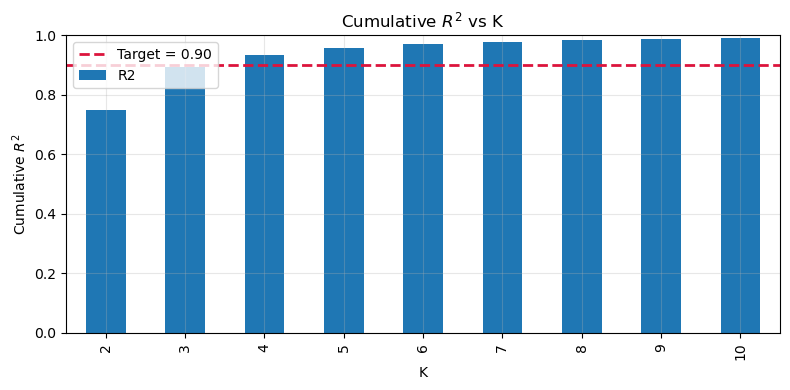

In [42]:
import matplotlib.pyplot as plt
target = 0.90

ax = results_df.plot(x="K", y="R2", kind="bar", figsize=(8,4), legend=False)
ax.axhline(target, color="crimson", linestyle="--", linewidth=2, label="Target = 0.90")

ax.set_xlabel("K")
ax.set_ylabel("Cumulative $R^2$")
ax.set_title("Cumulative $R^2$ vs K")
ax.set_ylim(0, 1.0)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## Defining the rung clusters

In [43]:
from sklearn.cluster import KMeans

# number of rungs given 90% target
K = 4 

# Build rungs at neighborhood level

df2 = nyc_scores.dropna(subset=["NTACode", "score_w"]).copy()
X = df2[["score_w"]].to_numpy()
km = KMeans(n_clusters=K, n_init=50, random_state=0)
df2["cluster_raw"] = km.fit_predict(X)

# Order clusters by centroid so rung 1 is lowest-score cluster
centroids = km.cluster_centers_.ravel()           # centroid per raw cluster id
order = np.argsort(centroids)                    # raw cluster ids sorted low->high
raw_to_rung = {raw: (rank + 1) for rank, raw in enumerate(order)}

df2["rung_km"] = df2["cluster_raw"].map(raw_to_rung).astype(int)

# "Respective value": centroid score for the rung
# First map raw cluster -> centroid, then raw -> rung (or directly rung -> centroid)
raw_to_centroid = {raw: centroids[raw] for raw in range(K)}
df2["rung_value"] = df2["cluster_raw"].map(raw_to_centroid)

rungs_by_neighborhood = df2[["NTACode", "rung_km", "rung_value"]].copy()

# Merge rungs back onto original dataset
df2_out = nyc_scores.merge(rungs_by_neighborhood, on="NTACode")
df2_out.head()

,NTACode,numer,denom,score_w,rung_km,rung_value
0,BK0101,19169.66156,38980,0.491782,3,0.476152
1,BK0102,22025.674072,53908,0.408579,2,0.422082
2,BK0103,14029.013368,37731,0.371817,1,0.367824
3,BK0104,23310.670014,52998,0.439841,2,0.422082
4,BK0201,11394.774831,25092,0.45412,3,0.476152


In [44]:
# rung-level summary
rung_summary = (df2.groupby("rung_km", as_index=False)
                  .agg(centroid=("rung_value", "mean"),
                       score_min=("score_w", "min"),
                       score_max=("score_w", "max"),
                       n_neighborhoods=("NTACode", "nunique")))
rung_summary

,rung_km,centroid,score_min,score_max,n_neighborhoods
0,1,0.367824,0.326442,0.394448,58
1,2,0.422082,0.396426,0.447085,45
2,3,0.476152,0.451417,0.509239,42
3,4,0.547024,0.512589,0.602811,52


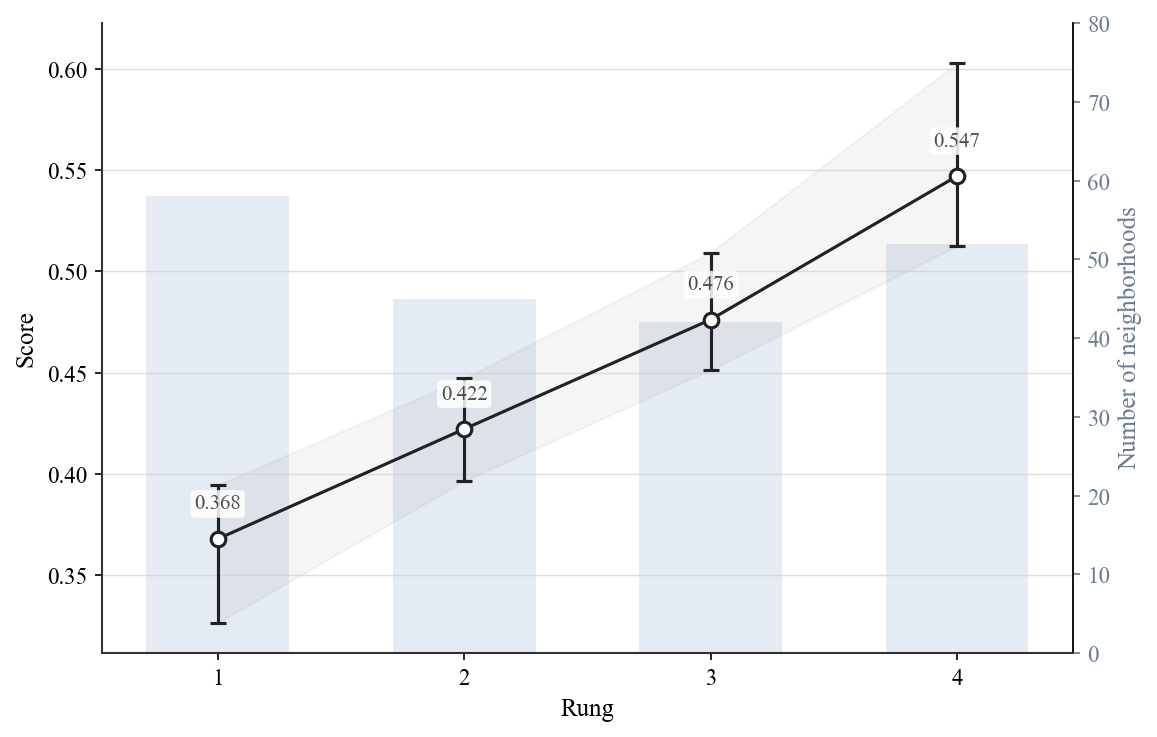

In [45]:
import matplotlib.pyplot as plt
import numpy as np

df = rung_summary.copy()

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif", "Liberation Serif", "serif"],
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "axes.spines.top": False,
})

x = df["rung_km"].values
y = df["centroid"].values
yerr_lower = y - df["score_min"].values
yerr_upper = df["score_max"].values - y
n = df["n_neighborhoods"].values

# Figure
fig, ax1 = plt.subplots(figsize=(7.6, 4.8), constrained_layout=True)
ax2 = ax1.twinx()

# Put the main score axis in front of the bar axis
ax1.set_zorder(3)
ax2.set_zorder(1)
ax1.patch.set_alpha(0)

bar_color = "#d7e1ee"
ax2.bar(
    x, n,
    width=0.58,
    color=bar_color,
    alpha=0.65,
    edgecolor="none",
    zorder=0
)

ax2.set_ylim(0, max(n) * 1.38)
ax2.set_ylabel("Number of neighborhoods", color="#6b7c93")
ax2.tick_params(axis="y", colors="#6b7c93")
ax2.spines["right"].set_color("#6b7c93")
ax2.spines["top"].set_visible(False)

# Min-max band
ax1.fill_between(
    x,
    df["score_min"].values,
    df["score_max"].values,
    color="gray",
    alpha=0.08,
    zorder=1
)

# Error bars and centroid line
main_color = "#222222"
ax1.errorbar(
    x, y,
    yerr=[yerr_lower, yerr_upper],
    fmt="o-",
    color=main_color,
    ecolor=main_color,
    elinewidth=1.5,
    capsize=4,
    capthick=1.2,
    markersize=7,
    linewidth=1.5,
    markerfacecolor="white",
    markeredgewidth=1.5,
    zorder=5
)

# Axis labels and ticks
ax1.set_xlabel("Rung")
ax1.set_ylabel("Score")
ax1.set_xticks(x)
ax1.set_xticklabels([str(i) for i in x])

ymin = min(df["score_min"]) - 0.015
ymax = max(df["score_max"]) + 0.02
ax1.set_ylim(ymin, ymax)

ax1.grid(axis="y", color="#d0d0d0", linewidth=0.7, alpha=0.7)
ax1.grid(axis="x", visible=False)

# Centroid labels
for xi, yi in zip(x, y):
    ax1.annotate(
        f"{yi:.3f}",
        xy=(xi, yi),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        color="#4d4d4d",
        zorder=10,
        bbox=dict(
            boxstyle="round,pad=0.18",
            facecolor="white",
            edgecolor="none",
            alpha=0.85
        ),
        clip_on=False
    )

# Spine styling
ax1.spines["left"].set_linewidth(1.0)
ax1.spines["bottom"].set_linewidth(1.0)
ax1.spines["left"].set_color("#333333")
ax1.spines["bottom"].set_color("#333333")

write_path = os.path.join(base_path, "figures", "score_by_rung_analysis.png")
#fig.savefig(write_path, bbox_inches="tight")
plt.show()


### Sanity checks

In [46]:
df2_out["rung_km"].describe()

count    197.000000
mean       2.446701
std        1.170841
min        1.000000
25%        1.000000
50%        2.000000
75%        4.000000
max        4.000000
Name: rung_km, dtype: float64

In [47]:
is_duplicated_in_any_column = pd.Series([False] * len(df2_out), index=df2_out.index)

for column in ["NTACode"]:
    is_duplicated_in_any_column = is_duplicated_in_any_column | df2_out[column].duplicated(keep=False)

# Filter the DataFrame to return only the rows that are marked as True
df_duplicates_any_col = df2_out[is_duplicated_in_any_column]

print("Rows with duplicates in at least one column:")
print(df_duplicates_any_col)

Rows with duplicates in at least one column:
Empty DataFrame
Columns: [NTACode, numer, denom, score_w, rung_km, rung_value]
Index: []


## Alternate rungs approach: Defining equal width rungs

In [48]:
# --- PARAMETERS ---
K = 4  # number of rungs
score_col = "score_w"
# --- COPY DATA ---
df3 = nyc_scores.copy()

# Compute bounds
s_min = df3["score_w"].min()
s_max = df3["score_w"].max()

# Define step size 
delta = (s_max - s_min) / K

# Assign rungs
x = (df3["score_w"] - s_min) / delta
x = pd.to_numeric(x, errors="coerce").replace([np.inf, -np.inf], np.nan)

df3["rung_eq"] = np.floor(x).astype("Int64") +1  

# Cap top rung (edge case where value == s_max)
df3["rung_eq"] = df3["rung_eq"].clip(upper=K)

# Define next best rung ---
df3["next_rung"] = df3["rung_eq"] + 1
df3.loc[df3["rung_eq"] == K, "next_rung"] = np.nan

df3.head()

,NTACode,numer,denom,score_w,rung_eq,next_rung
0,BK0101,19169.66156,38980,0.491782,3,4
1,BK0102,22025.674072,53908,0.408579,2,3
2,BK0103,14029.013368,37731,0.371817,1,2
3,BK0104,23310.670014,52998,0.439841,2,3
4,BK0201,11394.774831,25092,0.45412,2,3


In [49]:
df3[df3["rung_eq"].isna()]

,NTACode,numer,denom,score_w,rung_eq,next_rung


In [50]:
df3["rung_eq"].describe()

count       197.0
mean     2.269036
std      1.056421
min           1.0
25%           1.0
50%           2.0
75%           3.0
max           4.0
Name: rung_eq, dtype: Float64

In [51]:
df3["score_w"].describe()

count       197.0
mean     0.450615
std      0.071854
min      0.326442
25%      0.386184
50%      0.440427
75%      0.513888
max      0.602811
Name: score_w, dtype: Float64

In [52]:
print(list(set(df3["NTACode"])- set(df2_out["NTACode"])))
print(list(set(df2_out["NTACode"])- set(df3["NTACode"])))
print(len(df2_out))
print(len(df3))

[]
[]
197
197


In [53]:
compare = df3.merge(df2_out[["rung_km", "NTACode"]], how="left", on="NTACode")
compare[compare['rung_eq'] != compare['rung_km']].sort_values("score_w")[["NTACode","score_w", "rung_eq","rung_km"]]

,NTACode,score_w,rung_eq,rung_km
39,BK1402,0.451417,2,3
73,BX0802,0.452344,2,3
134,QN0402,0.453172,2,3
173,QN1303,0.454068,2,3
4,BK0201,0.45412,2,3
158,QN1001,0.454193,2,3
19,BK0701,0.45741,2,3
80,BX1002,0.458357,2,3
105,MN0604,0.459658,2,3
106,MN0701,0.460125,2,3


## Visualizing against NYC neighborhood maps

In [54]:
base = (
    "https://services5.arcgis.com/GfwWNkhOj9bNBqoJ/ArcGIS/rest/services/"
    "nyc_neighborhood_tabulation_areas_2020/FeatureServer/0/query"
)

params = {
    "where": "1=1",
    "outFields": "*",
    "outSR": 4326,
    "f": "geojson",
    "orderByFields": "OBJECTID",   # important for stable paging (field name is often OBJECTID)
    "resultRecordCount": 200,
    "resultOffset": 0,
}

features = []
while True:
    r = requests.get(base, params=params, timeout=120) 
    r.raise_for_status()
    js = r.json()
    batch = js.get("features", [])
    if not batch:
        break
    features.extend(batch)
    params["resultOffset"] += len(batch)

nta_gdf = gpd.GeoDataFrame.from_features(features, crs="EPSG:4326")
nta_gdf.geometry.isna().sum(), len(nta_gdf)

(np.int64(0), 262)

In [55]:
nta_gdf.head()

,geometry,OBJECTID,BoroCode,BoroName,CountyFIPS,NTA2020,NTAName,NTAAbbrev,NTAType,CDTA2020,CDTAName,Shape__Area,Shape__Length
0,"POLYGON ((-73.93214 40.72817, -73.93238 40.728...",1,3,Brooklyn,047,BK0101,Greenpoint,Grnpt,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),3.532181e+07,28919.560728
1,"POLYGON ((-73.95814 40.72441, -73.95772 40.724...",2,3,Brooklyn,047,BK0102,Williamsburg,Wllmsbrg,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),2.885285e+07,28134.082680
2,"POLYGON ((-73.95024 40.70548, -73.94984 40.705...",3,3,Brooklyn,047,BK0103,South Williamsburg,SWllmsbrg,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),1.520896e+07,18250.280091
3,"POLYGON ((-73.92406 40.71412, -73.92404 40.714...",4,3,Brooklyn,047,BK0104,East Williamsburg,EWllmsbrg,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),5.226741e+07,43184.800375
4,"POLYGON ((-73.99237 40.6897, -73.99436 40.6902...",5,3,Brooklyn,047,BK0201,Brooklyn Heights,BkHts,0,BK02,BK02 Downtown Brooklyn-Fort Greene (CD 2 Appro...,9.982023e+06,14312.192285


In [56]:
## using kmeans labels from here on out
nta_scores = df2_out.copy() 
map_gdf = pd.DataFrame()

nta_code_poly = "NTA2020"   
nta_code_tbl  = "NTACode"        

nta_gdf[nta_code_poly] = nta_gdf[nta_code_poly].astype(str).str.strip()
nta_scores[nta_code_tbl] = nta_scores[nta_code_tbl].astype(str).str.strip()

map_gdf = nta_gdf.merge(
    nta_scores,
    left_on=nta_code_poly,
    right_on=nta_code_tbl,
    how="left"
)
map_gdf.head()

,geometry,OBJECTID,BoroCode,BoroName,CountyFIPS,NTA2020,NTAName,NTAAbbrev,NTAType,CDTA2020,CDTAName,Shape__Area,Shape__Length,NTACode,numer,denom,score_w,rung_km,rung_value
0,"POLYGON ((-73.93214 40.72817, -73.93238 40.728...",1,3,Brooklyn,047,BK0101,Greenpoint,Grnpt,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),3.532181e+07,28919.560728,BK0101,19169.66156,38980,0.491782,3.0,0.476152
1,"POLYGON ((-73.95814 40.72441, -73.95772 40.724...",2,3,Brooklyn,047,BK0102,Williamsburg,Wllmsbrg,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),2.885285e+07,28134.082680,BK0102,22025.674072,53908,0.408579,2.0,0.422082
2,"POLYGON ((-73.95024 40.70548, -73.94984 40.705...",3,3,Brooklyn,047,BK0103,South Williamsburg,SWllmsbrg,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),1.520896e+07,18250.280091,BK0103,14029.013368,37731,0.371817,1.0,0.367824
3,"POLYGON ((-73.92406 40.71412, -73.92404 40.714...",4,3,Brooklyn,047,BK0104,East Williamsburg,EWllmsbrg,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),5.226741e+07,43184.800375,BK0104,23310.670014,52998,0.439841,2.0,0.422082
4,"POLYGON ((-73.99237 40.6897, -73.99436 40.6902...",5,3,Brooklyn,047,BK0201,Brooklyn Heights,BkHts,0,BK02,BK02 Downtown Brooklyn-Fort Greene (CD 2 Appro...,9.982023e+06,14312.192285,BK0201,11394.774831,25092,0.45412,3.0,0.476152


### Sanity checks

In [57]:
map_gdf["score_w"].isna().sum(), len(map_gdf)

(np.int64(65), 262)

In [58]:
unmatched = map_gdf.loc[map_gdf["score_w"].isna(), "NTA2020"].unique()
print(len(unmatched))
#no effect as these are parks/islands/cemeteries etc
unmatched_codes = unmatched 
map_gdf.loc[
    map_gdf["NTA2020"].isin(unmatched_codes),
    ["NTA2020", "NTAName","NTAType", "BoroName"]
].sort_values(["BoroName","NTA2020"])["NTAType"].unique()

65


array(['9', '7', '6', '5', '8'], dtype=object)

In [59]:
map_gdf = map_gdf[map_gdf["NTAType"]=="0"]
map_gdf.head()

,geometry,OBJECTID,BoroCode,BoroName,CountyFIPS,NTA2020,NTAName,NTAAbbrev,NTAType,CDTA2020,CDTAName,Shape__Area,Shape__Length,NTACode,numer,denom,score_w,rung_km,rung_value
0,"POLYGON ((-73.93214 40.72817, -73.93238 40.728...",1,3,Brooklyn,047,BK0101,Greenpoint,Grnpt,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),3.532181e+07,28919.560728,BK0101,19169.66156,38980,0.491782,3.0,0.476152
1,"POLYGON ((-73.95814 40.72441, -73.95772 40.724...",2,3,Brooklyn,047,BK0102,Williamsburg,Wllmsbrg,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),2.885285e+07,28134.082680,BK0102,22025.674072,53908,0.408579,2.0,0.422082
2,"POLYGON ((-73.95024 40.70548, -73.94984 40.705...",3,3,Brooklyn,047,BK0103,South Williamsburg,SWllmsbrg,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),1.520896e+07,18250.280091,BK0103,14029.013368,37731,0.371817,1.0,0.367824
3,"POLYGON ((-73.92406 40.71412, -73.92404 40.714...",4,3,Brooklyn,047,BK0104,East Williamsburg,EWllmsbrg,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),5.226741e+07,43184.800375,BK0104,23310.670014,52998,0.439841,2.0,0.422082
4,"POLYGON ((-73.99237 40.6897, -73.99436 40.6902...",5,3,Brooklyn,047,BK0201,Brooklyn Heights,BkHts,0,BK02,BK02 Downtown Brooklyn-Fort Greene (CD 2 Appro...,9.982023e+06,14312.192285,BK0201,11394.774831,25092,0.45412,3.0,0.476152


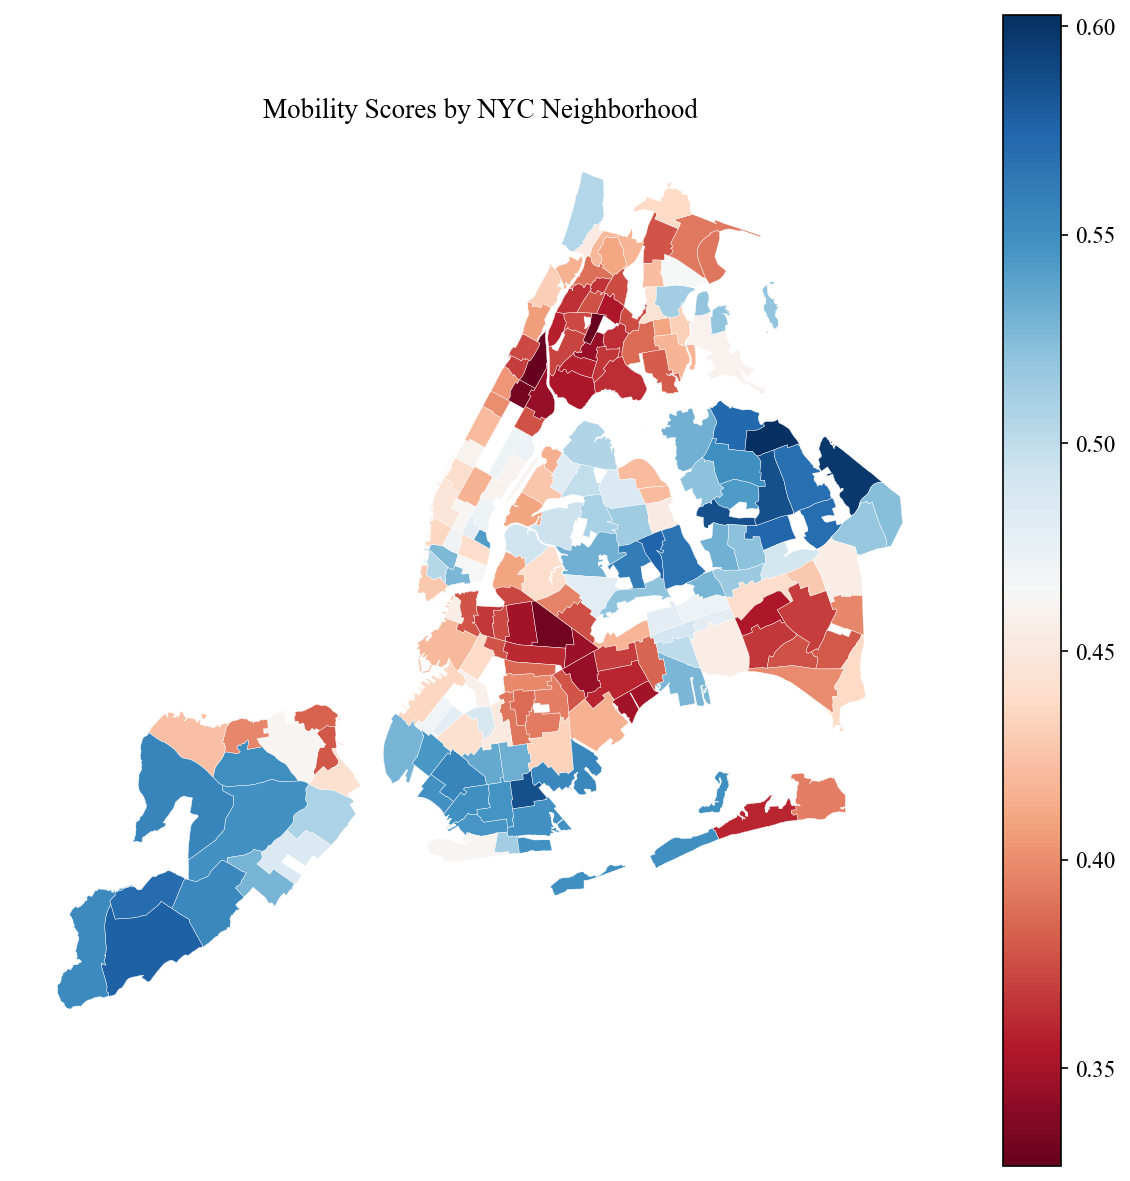

In [60]:
map_gdf["nta_score"] = pd.to_numeric(map_gdf["score_w"], errors="coerce")
ax = map_gdf.to_crs(2263).plot(
    column="nta_score",
    cmap="RdBu",
    legend=True,
    figsize=(10, 10),
    linewidth=0.2,
    edgecolor="white",
    missing_kwds={"color": "lightgrey", "label": "No data / special area"}
)
ax.set_axis_off()
ax.set_title("Mobility Scores by NYC Neighborhood")
fig = ax.get_figure()
write_path = os.path.join(base_path,"figures", "map_nta_score.png")
#fig.savefig(write_path, dpi=300, bbox_inches="tight", pad_inches=.5)


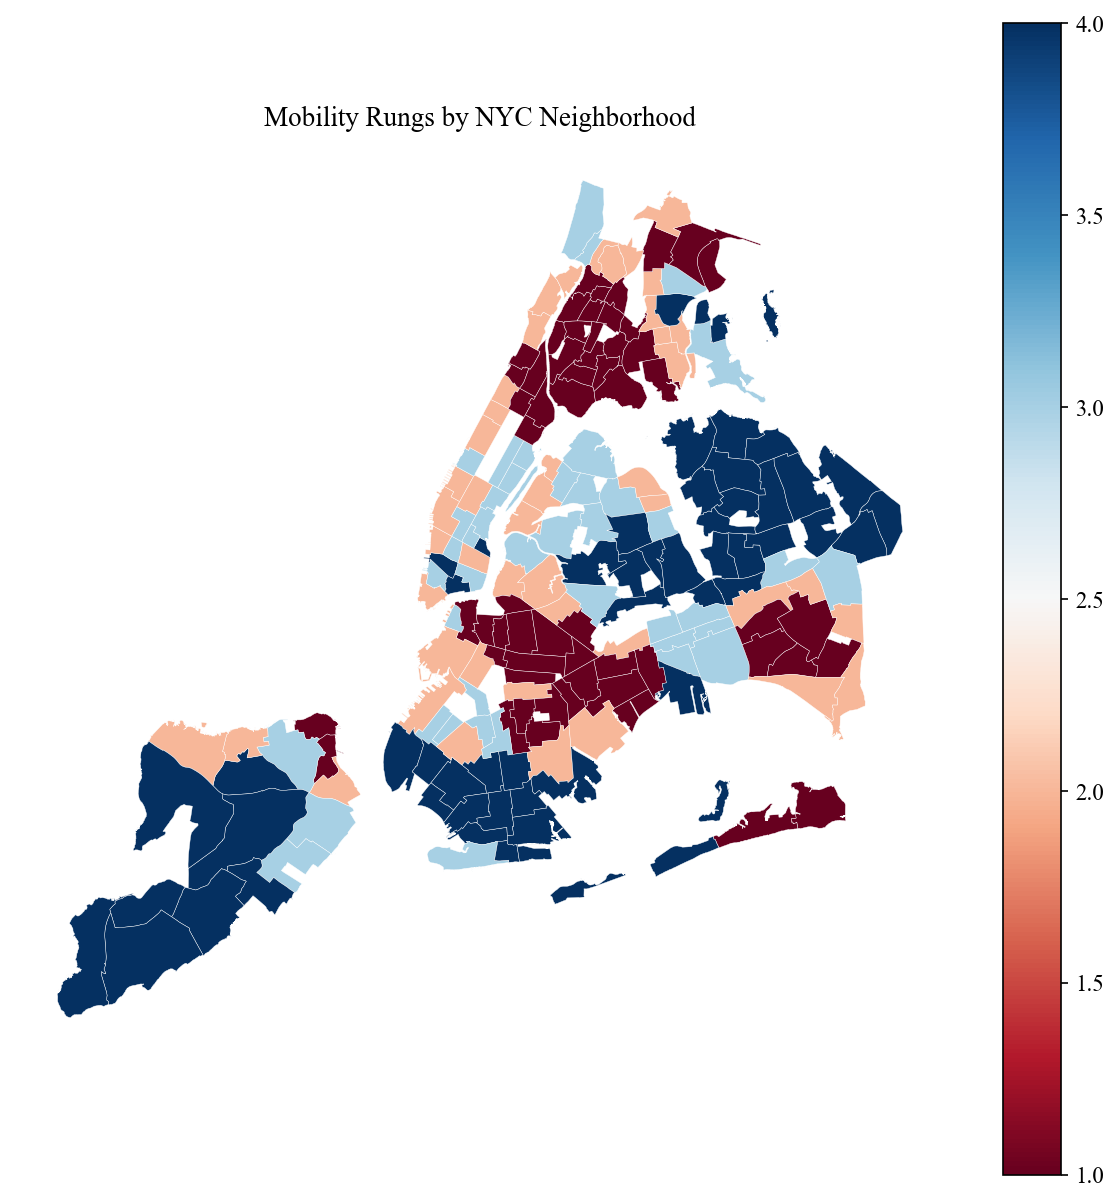

In [61]:
ax = map_gdf.to_crs(2263).plot(
    column="rung_km",
    cmap="RdBu",
    legend=True,
    figsize=(10, 10),
    linewidth=0.2,
    edgecolor="white",
    missing_kwds={"color": "lightgrey", "label": "No data / special area"}
)
ax.set_axis_off()
ax.set_title("Mobility Rungs by NYC Neighborhood")
fig = ax.get_figure()

write_path = os.path.join(base_path,"figures", "map_km_rung.png")
#fig.savefig(write_path, dpi=300, bbox_inches="tight", pad_inches=.5)


## Overlaying the MTA Subway Stations

In [62]:
import requests
url = "http://web.mta.info/developers/data/nyct/subway/google_transit.zip" 
out  = os.path.join(base_path,"data_raw", "google_transit.zip")

with requests.get(url, stream=True, timeout=120) as r:
    r.raise_for_status()
    with open(out, "wb") as f:
        for chunk in r.iter_content(chunk_size=1024*1024):
            if chunk:
                f.write(chunk)

In [63]:
gtfs_zip = os.path.join(base_path,"data_raw", "google_transit.zip")

with zipfile.ZipFile(gtfs_zip) as z:
    stops = pd.read_csv(z.open("stops.txt"), dtype=str)
    stop_times = pd.read_csv(z.open("stop_times.txt"), dtype=str)
    trips = pd.read_csv(z.open("trips.txt"), dtype=str)

stops["stop_lat"] = stops["stop_lat"].astype(float)
stops["stop_lon"] = stops["stop_lon"].astype(float)

stops_gdf = gpd.GeoDataFrame(
    stops,
    geometry=gpd.points_from_xy(stops["stop_lon"], stops["stop_lat"]),
    crs="EPSG:4326"
).to_crs(2263)

In [64]:
nta_plot = map_gdf.to_crs(2263)
stops_plot = stops_gdf.to_crs(2263)

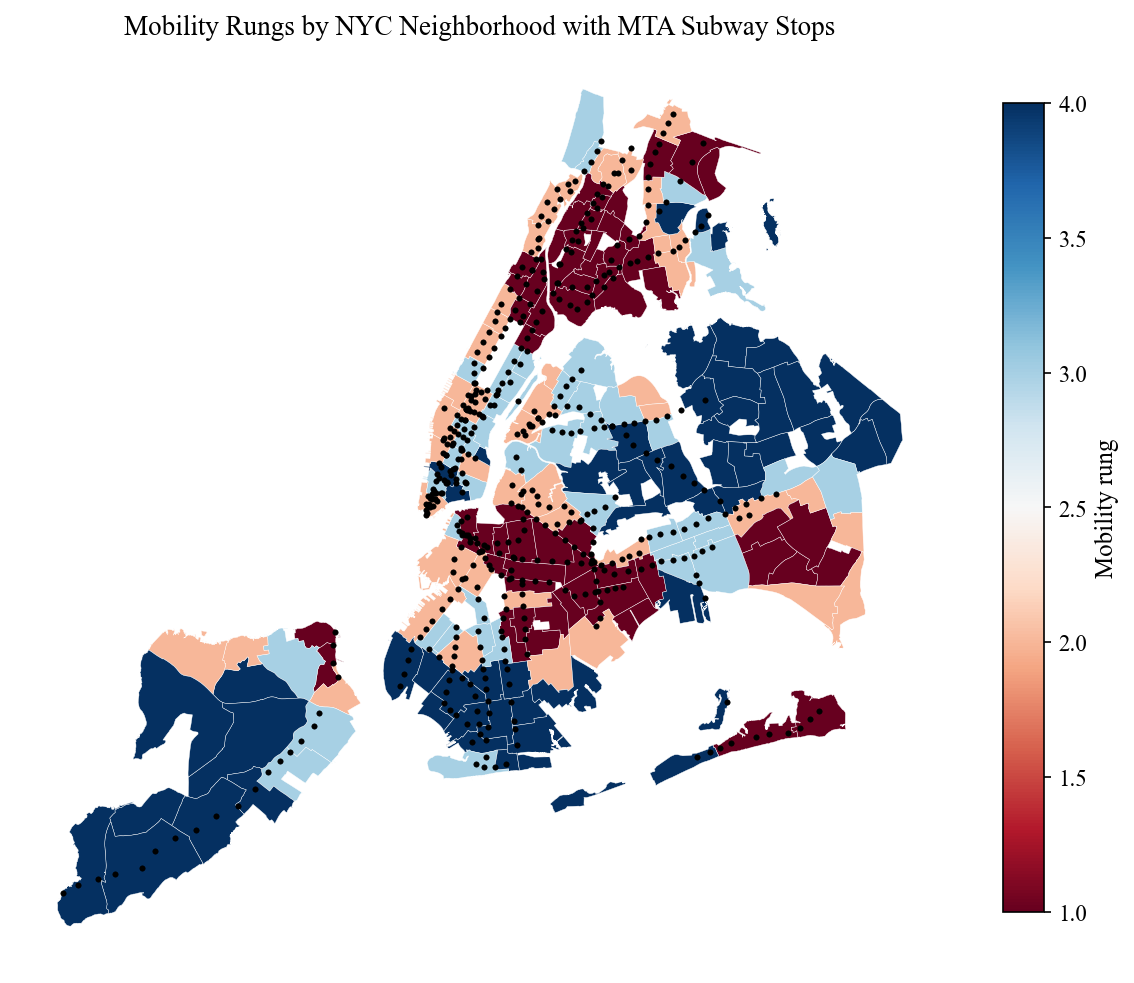

In [65]:
ax = nta_plot.plot(
    column="rung_km",
    cmap="RdBu",
    legend=True,
    figsize=(10, 10),
    linewidth=0.2,
    edgecolor="white",
    missing_kwds={"color": "lightgrey", "label": "No data / special area"},
    legend_kwds={"label": "Mobility rung", "shrink": 0.7}
)

stops_plot.plot(
    ax=ax,
    color="black",
    markersize=3,   # adjust size
    alpha=0.7
)

ax.set_axis_off()
ax.set_title("Mobility Rungs by NYC Neighborhood with MTA Subway Stops")
fig = ax.get_figure()
#fig.savefig(os.path.join(base_path,"figures", "map_km_rung_w_mta.png"), dpi=300, bbox_inches="tight", pad_inches=.5)

## Approximating time to get from each origin to destination

In [66]:
nta_pts = nta_gdf.to_crs(2263).copy()
nta_pts["pt"] = nta_pts.geometry.representative_point()
nta_pts = nta_pts.set_geometry("pt") 
stops_2263 = stops_gdf.to_crs(2263).copy()

In [67]:
print("nta:", nta_pts.crs)
print("stops:", stops_2263.crs)

nta: EPSG:2263
stops: EPSG:2263


In [68]:
# --- constants ---
K = 5
WALK_MPS = 1.4  # walking speed (meters / second)

# EPSG:2263 distances are in US survey feet
US_SURVEY_FT_TO_M = 0.3048006096

def nearest_k_stops(point, k=K):
    # distances in US survey feet (because CRS is EPSG:2263)
    d_ft = stops_2263.distance(point)
    ix = d_ft.nsmallest(k).index
    out = stops_2263.loc[ix, ["stop_id"]].copy()
    # convert feet -> meters -> seconds at WALK_MPS
    out["walk_sec"] = (d_ft.loc[ix].to_numpy() * US_SURVEY_FT_TO_M) / WALK_MPS
    return out

# build NTA -> nearest stops table 
rows = []
for _, r in nta_pts[["NTA2020", "pt"]].iterrows():
    tmp = nearest_k_stops(r["pt"], k=K)
    tmp["NTA2020"] = r["NTA2020"]
    rows.append(tmp)

nta_access = pd.concat(rows, ignore_index=True)[["NTA2020", "stop_id", "walk_sec"]]

#  dictionary for fast lookup later 
access_by_nta = {
    nta: grp[["stop_id", "walk_sec"]].to_records(index=False)
    for nta, grp in nta_access.groupby("NTA2020")
}

In [69]:
# Parse GTFS times
def hhmmss_to_seconds(x):
    if x is None or pd.isna(x):
        return pd.NA
    x = str(x).strip()
    if not x:
        return pd.NA

    parts = x.split(":")
    if len(parts) != 3:
        return pd.NA

    try:
        h, m, s = (int(parts[0]), int(parts[1]), int(parts[2]))
    except ValueError:
        return pd.NA

    return h * 3600 + m * 60 + s


# Compute travel time between consecutive stops

# Keep only stop_times for trips we care about
trip_ids = trips["trip_id"].dropna().unique()
st = stop_times.loc[stop_times["trip_id"].isin(trip_ids)].copy()

# Ensure numeric stop order
st["stop_sequence"] = pd.to_numeric(st["stop_sequence"], errors="coerce").astype("Int64")
st = st.dropna(subset=["stop_sequence"])

# Prefer departure_time; fall back to arrival_time if departure is missing
time_str = st["departure_time"].fillna(st.get("arrival_time"))
st = st.assign(t=time_str.map(hhmmss_to_seconds))
st = st.dropna(subset=["t"])

# Sort within each trip
st = st.sort_values(["trip_id", "stop_sequence"])

# Consecutive stop pairs within each trip
st["v"] = st.groupby("trip_id")["stop_id"].shift(-1)
st["t_next"] = st.groupby("trip_id")["t"].shift(-1)

pairs = st.dropna(subset=["v", "t_next"]).copy()
pairs = pairs.rename(columns={"stop_id": "u"})
pairs["dt"] = pairs["t_next"] - pairs["t"]

# Keep only sane, positive travel times (drop zero/negative and bad rows)
pairs = pairs[pairs["dt"].notna() & (pairs["dt"] > 0)]

# Typical time per directed edge (u -> v)
edge_times = (
    pairs.groupby(["u", "v"], as_index=False)["dt"]
         .median()
         .rename(columns={"dt": "sec"})
)

edge_times

,u,v,sec
0,101S,103S,90.0
1,103N,101N,90.0
2,103S,104S,90.0
3,104N,103N,210.0
4,104S,106S,90.0
...,...,...,...
1144,S29S,S28S,120.0
1145,S30N,S31N,180.0
1146,S30S,S29S,120.0
1147,S31S,S19S,960.0


In [70]:
# Create the NetworkX graph
G = nx.DiGraph()

stops_df = stops_plot  

# Ensure consistent stop_id types
stops_df = stops_df.copy()
stops_df["stop_id"] = stops_df["stop_id"].astype(str)

# Build an explicit 'edges' table from edge_times
edges = edge_times.copy()
edges["u"] = edges["u"].astype(str)
edges["v"] = edges["v"].astype(str)
edges["sec"] = pd.to_numeric(edges["sec"], errors="coerce")

# Add nodes
G.add_nodes_from(stops_df["stop_id"].tolist())

# Add directed edges with travel times (seconds)
for u, v, sec in edges[["u", "v", "sec"]].itertuples(index=False, name=None):
    if pd.notna(sec) and sec > 0:
        w = float(sec)
        # don't overwrite an existing smaller weight
        if G.has_edge(u, v):
            G[u][v]["weight"] = min(G[u][v]["weight"], w)
        else:
            G.add_edge(u, v, weight=w)

# Add transfers (necessary for connectivity) 
TRANSFER_SEC = 120.0

if "parent_station" in stops_df.columns:
    ps = stops_df.dropna(subset=["parent_station"])[["stop_id", "parent_station"]].copy()
    ps["parent_station"] = ps["parent_station"].astype(str)

    for _, grp in ps.groupby("parent_station"):
        ids = grp["stop_id"].tolist()
        n = len(ids)
        for i in range(n):
            a = ids[i]
            for j in range(i + 1, n):
                b = ids[j]
                for x, y in ((a, b), (b, a)):
                    if G.has_edge(x, y):
                        G[x][y]["weight"] = min(G[x][y]["weight"], TRANSFER_SEC)
                    else:
                        G.add_edge(x, y, weight=TRANSFER_SEC)


In [71]:
SRC = "__SRC__"
if SRC not in G:
    G.add_node(SRC)

# all NTAs that have access stops
nta_list = list(access_by_nta.keys())

travel_rows = []

for origin in nta_list:
    # clear any previous iteration's SRC outgoing edges
    G.remove_edges_from(list(G.out_edges(SRC)))

    # add walking edges: SRC -> origin access stops (walk-in)
    for stop_id, walk_in_sec in access_by_nta[origin]:
        sid = str(stop_id)  # keep consistent with graph node ids
        if sid in G:
            G.add_edge(SRC, sid, weight=float(walk_in_sec))

    # shortest path from SRC to all reachable stops
    dist = nx.single_source_dijkstra_path_length(G, SRC, weight="weight")

    # evaluate every destination NTA: min_{dest access stop} dist(stop) + walk-out
    for dest in nta_list:
        best = np.inf
        for stop_id, walk_out_sec in access_by_nta[dest]:
            sid = str(stop_id)
            if sid in dist:
                cand = dist[sid] + float(walk_out_sec)
                if cand < best:
                    best = cand

        if np.isfinite(best):
            travel_rows.append({"origin": origin, "dest": dest, "travel_sec": best})

travel_costs = pd.DataFrame(travel_rows)

In [72]:
# quick check
print("travel_costs shape:", travel_costs.shape)
print("travel_costs columns:", travel_costs.columns.tolist())

travel_costs shape: (31422, 3)
travel_costs columns: ['origin', 'dest', 'travel_sec']


In [73]:
# Merge (origin NTA, dest NTA) pairs with the computed transit travel times

od_pairs = edges.copy()

# enforce naming conventions used above
rename_map = {
    "u": "origin",
    "v": "dest",
    "from": "origin",
    "to": "dest",
    "NTA2020_origin": "origin",
    "NTA2020_dest": "dest",
}
od_pairs = od_pairs.rename(columns={k: v for k, v in rename_map.items() if k in od_pairs.columns})

# keep only required columns
od_pairs = od_pairs[["origin", "dest"]].drop_duplicates()

edges_subway = od_pairs.merge(travel_costs, on=["origin", "dest"], how="left")

# --- best destination (minimum travel time) per origin ---
if travel_costs.empty:
    best_by_time = pd.DataFrame(columns=["origin", "dest", "travel_sec"])
else:
    best_by_time = (
        travel_costs
        .dropna(subset=["travel_sec"])
        .query("origin != dest")
        .loc[lambda df: df.groupby("origin")["travel_sec"].idxmin()]
        .reset_index(drop=True)
    )

In [74]:
travel_costs.loc[travel_costs["origin"] == travel_costs["dest"], "travel_sec"] = 0.0
travel_costs["travel_min"]=travel_costs["travel_sec"]/60
travel_costs = travel_costs[travel_costs["travel_sec"]!=0]

## Merging rungs to travel time to rank by score and time

In [75]:
tc = travel_costs.copy()
tc["origin"] = tc["origin"].astype(str).str.strip()
tc["dest"]   = tc["dest"].astype(str).str.strip()

# Build a unique NTA -> rung table
NTA_COL = "NTACode"
RUNG_COL = "rung_km"

nta_rungs = df2_out[[NTA_COL, RUNG_COL]].copy()
nta_rungs[NTA_COL] = nta_rungs[NTA_COL].astype(str).str.strip()
nta_rungs[RUNG_COL] = pd.to_numeric(nta_rungs[RUNG_COL], errors="coerce")

# ensure one row per NTA (required for m:1 validation)
nta_rungs = nta_rungs.drop_duplicates(subset=[NTA_COL]).rename(columns={NTA_COL: "nta", RUNG_COL: "rung"})

#  Merge rungs onto travel_costs
travel_with_rungs = (
    tc.merge(nta_rungs.rename(columns={"nta": "origin", "rung": "origin_rung"}),
             on="origin", how="left", validate="m:1")
      .merge(nta_rungs.rename(columns={"nta": "dest", "rung": "dest_rung"}),
             on="dest", how="left", validate="m:1")
)

### Sanity checks

In [76]:
print("travel_costs rows:", len(tc))
print("travel_with_rungs rows:", len(travel_with_rungs))
print("missing origin_rung:", travel_with_rungs["origin_rung"].isna().sum())
print("missing dest_rung:", travel_with_rungs["dest_rung"].isna().sum())

travel_costs rows: 31160
travel_with_rungs rows: 31160
missing origin_rung: 7127
missing dest_rung: 7127


### All data

In [77]:
#  filter to "next rung" and compute best destination per origin ---
cand = travel_with_rungs.dropna(subset=["travel_sec", "origin_rung", "dest_rung"]).copy()
cand = cand[cand["origin"] != cand["dest"]]

cand["origin_rung"] = cand["origin_rung"].astype(int)
cand["dest_rung"]   = cand["dest_rung"].astype(int)
cand.head()

,origin,dest,travel_sec,travel_min,origin_rung,dest_rung
0,BK0101,BK0102,1227.220331,20.453672,3,2
1,BK0101,BK0103,3314.063508,55.234392,3,1
2,BK0101,BK0201,3313.307849,55.221797,3,3
3,BK0101,BK0202,1684.360741,28.072679,3,1
4,BK0101,BK0203,1435.602285,23.926705,3,1


In [78]:
cand = cand.sort_values(["origin", "travel_sec"], ascending=[True, True]).copy()
cand["all_dest_time_rank"] = cand.groupby("origin").cumcount() + 1   # this is just an order rank

In [79]:
#get neighborhood scores
SCORE_COL = "score_w"
NTA_COL = "NTACode"

nta_lu = (
    df2_out[[NTA_COL, SCORE_COL]]
    .copy()
    .drop_duplicates(subset=[NTA_COL])
    .rename(columns={
        NTA_COL: "nta",
        SCORE_COL: "score",
    })
)

# Clean join keys
nta_lu["nta"] = nta_lu["nta"].astype(str).str.strip()

out = cand.copy()
out["origin"] = out["origin"].astype(str).str.strip()
out["dest"]   = out["dest"].astype(str).str.strip()

# Merge origin attributes
out = out.merge(
    nta_lu.rename(columns={
        "nta": "origin",
        "nta_name": "origin_name",
        "score": "origin_score",
    }),
    on="origin",
    how="left",
    validate="m:1",
)

# Merge destination attributes
out = out.merge(
    nta_lu.rename(columns={
        "nta": "dest",
        "nta_name": "dest_name",
        "rung": "dest_rung",
        "score": "dest_score",
    }),
    on="dest",
    how="left",
    validate="m:1",
)

print(len(out) == len(cand))

True


In [80]:
#get neighborhood names
NTA_NAME = "NTAName"
NTA_COL = "NTACode"

nta_lu = (
    eq[[NTA_COL, NTA_NAME]]
    .copy()
    .drop_duplicates(subset=[NTA_COL])
    .rename(columns={
        NTA_COL: "nta",
        NTA_NAME: "nta_name",
    })
)

# Clean join keys
nta_lu["nta"] = nta_lu["nta"].astype(str).str.strip()

out["origin"] = out["origin"].astype(str).str.strip()
out["dest"]   = out["dest"].astype(str).str.strip()

# Merge origin attributes
out = out.merge(
    nta_lu.rename(columns={
        "nta": "origin",
        "nta_name": "origin_name",
    }),
    on="origin",
    how="left",
    validate="m:1")

# Merge destination attributes
out = out.merge(
    nta_lu.rename(columns={
        "nta": "dest",
        "nta_name": "dest_name",

    }),
    on="dest",
    how="left",
    validate="m:1"
)

print(len(out) == len(cand))

True


In [81]:
cand = out.copy()
cand.head()

,origin,dest,travel_sec,travel_min,origin_rung,dest_rung,all_dest_time_rank,origin_score,dest_score,origin_name,dest_name
0,BK0101,QN0201,799.586391,13.326440,3,2,1,0.491782,0.408501,Greenpoint,Long Island City-Hunters Point
1,BK0101,BK0301,1065.437898,17.757298,3,1,2,0.491782,0.34805,Greenpoint,Bedford-Stuyvesant (West)
2,BK0101,BK0204,1212.192661,20.203211,3,1,3,0.491782,0.37345,Greenpoint,Clinton Hill
3,BK0101,BK0102,1227.220331,20.453672,3,2,4,0.491782,0.408579,Greenpoint,Williamsburg
4,BK0101,BK0203,1435.602285,23.926705,3,1,5,0.491782,0.366761,Greenpoint,Fort Greene


In [82]:
#differences in score
cand = cand[cand["origin"] != cand["dest"]]
cand["delta_rung"] = cand["dest_rung"] - cand["origin_rung"]
cand["score_diff"] = cand["dest_score"] - cand["origin_score"]
cand["min_travel_flag"] = (cand["travel_min"]==cand.groupby("origin")["travel_min"].transform("min")).astype(int)
cand.head()

,origin,dest,travel_sec,travel_min,origin_rung,dest_rung,all_dest_time_rank,origin_score,dest_score,origin_name,dest_name,delta_rung,score_diff,min_travel_flag
0,BK0101,QN0201,799.586391,13.326440,3,2,1,0.491782,0.408501,Greenpoint,Long Island City-Hunters Point,-1,-0.083281,1
1,BK0101,BK0301,1065.437898,17.757298,3,1,2,0.491782,0.34805,Greenpoint,Bedford-Stuyvesant (West),-2,-0.143732,0
2,BK0101,BK0204,1212.192661,20.203211,3,1,3,0.491782,0.37345,Greenpoint,Clinton Hill,-2,-0.118332,0
3,BK0101,BK0102,1227.220331,20.453672,3,2,4,0.491782,0.408579,Greenpoint,Williamsburg,-1,-0.083203,0
4,BK0101,BK0203,1435.602285,23.926705,3,1,5,0.491782,0.366761,Greenpoint,Fort Greene,-2,-0.125021,0


In [83]:
#where dest rung =+1 or greater from origin, show gain
cand["dest_pos_delta_rung_flag"] = np.where(
    cand["dest_rung"] > cand["origin_rung"],
    1, 0
)

mask = cand["dest_pos_delta_rung_flag"].eq(1)

cand["abs_gain"] = np.nan
cand.loc[mask, "abs_gain"] = cand.loc[mask, "dest_score"] - cand.loc[mask, "origin_score"]

cand.head()

,origin,dest,travel_sec,travel_min,origin_rung,dest_rung,all_dest_time_rank,origin_score,dest_score,origin_name,dest_name,delta_rung,score_diff,min_travel_flag,dest_pos_delta_rung_flag,abs_gain
0,BK0101,QN0201,799.586391,13.326440,3,2,1,0.491782,0.408501,Greenpoint,Long Island City-Hunters Point,-1,-0.083281,1,0,NaN
1,BK0101,BK0301,1065.437898,17.757298,3,1,2,0.491782,0.34805,Greenpoint,Bedford-Stuyvesant (West),-2,-0.143732,0,0,NaN
2,BK0101,BK0204,1212.192661,20.203211,3,1,3,0.491782,0.37345,Greenpoint,Clinton Hill,-2,-0.118332,0,0,NaN
3,BK0101,BK0102,1227.220331,20.453672,3,2,4,0.491782,0.408579,Greenpoint,Williamsburg,-1,-0.083203,0,0,NaN
4,BK0101,BK0203,1435.602285,23.926705,3,1,5,0.491782,0.366761,Greenpoint,Fort Greene,-2,-0.125021,0,0,NaN


In [84]:
#use time to get efficiency
cand["score_time_efficiency"] = np.nan
cand.loc[mask, "score_time_efficiency"] = cand.loc[mask, "abs_gain"]  / cand.loc[mask, "travel_min"]
cand.head()

cand["score_time_eff_rank"] = np.nan

cand.loc[mask, "score_time_eff_rank"] = (
    cand.loc[mask]
    .groupby("origin")["score_time_efficiency"]
    .rank(method="first", ascending=False)
    .astype(int)
)
cand[cand["score_time_eff_rank"].notna()].sort_values(["origin","score_time_eff_rank"])

,origin,dest,travel_sec,travel_min,origin_rung,dest_rung,all_dest_time_rank,origin_score,dest_score,origin_name,dest_name,delta_rung,score_diff,min_travel_flag,dest_pos_delta_rung_flag,abs_gain,score_time_efficiency,score_time_eff_rank
72,BK0101,BK1502,4348.110731,72.468512,3,4,73,0.491782,0.586059,Greenpoint,Madison,1,0.094277,0,1,0.094277,0.001301,1.0
7,BK0101,MN0301,1899.809799,31.663497,3,4,8,0.491782,0.528278,Greenpoint,Chinatown-Two Bridges,1,0.036496,0,1,0.036496,0.001153,2.0
70,BK0101,QN0601,4336.106309,72.268438,3,4,71,0.491782,0.574927,Greenpoint,Rego Park,1,0.083145,0,1,0.083145,0.001151,3.0
57,BK0101,QN0602,4002.501033,66.708351,3,4,58,0.491782,0.566192,Greenpoint,Forest Hills,1,0.07441,0,1,0.074410,0.001115,4.0
17,BK0101,BK1204,2506.615081,41.776918,3,4,18,0.491782,0.535229,Greenpoint,Mapleton-Midwood (West),1,0.043447,0,1,0.043447,0.001040,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18369,SI0202,SI0203,1346.182618,22.436377,3,4,4,0.48547,0.548753,New Dorp-Midland Beach,Todt Hill-Emerson Hill-Lighthouse Hill-Manor H...,1,0.063283,0,1,0.063283,0.002821,4.0
18375,SI0202,SI0303,2378.771880,39.646198,3,4,10,0.48547,0.571453,New Dorp-Midland Beach,Arden Heights-Rossville,1,0.085983,0,1,0.085983,0.002169,5.0
18374,SI0202,SI0305,1974.347181,32.905786,3,4,9,0.48547,0.552179,New Dorp-Midland Beach,Tottenville-Charleston,1,0.066709,0,1,0.066709,0.002027,6.0
18377,SI0202,SI0204,3554.647020,59.244117,3,4,12,0.48547,0.555999,New Dorp-Midland Beach,New Springville-Willowbrook-Bulls Head-Travis,1,0.070529,0,1,0.070529,0.001190,7.0


In [85]:
cand = cand[['origin',"origin_name","origin_score", 'dest', "dest_name","dest_score",'score_diff', 'abs_gain', 'travel_sec', 'travel_min','all_dest_time_rank', 'min_travel_flag', 'origin_rung',
       'dest_rung',  'delta_rung',  'dest_pos_delta_rung_flag', 'score_time_efficiency','score_time_eff_rank']]
cand.head()

,origin,origin_name,origin_score,dest,dest_name,dest_score,score_diff,abs_gain,travel_sec,travel_min,all_dest_time_rank,min_travel_flag,origin_rung,dest_rung,delta_rung,dest_pos_delta_rung_flag,score_time_efficiency,score_time_eff_rank
0,BK0101,Greenpoint,0.491782,QN0201,Long Island City-Hunters Point,0.408501,-0.083281,NaN,799.586391,13.326440,1,1,3,2,-1,0,NaN,NaN
1,BK0101,Greenpoint,0.491782,BK0301,Bedford-Stuyvesant (West),0.34805,-0.143732,NaN,1065.437898,17.757298,2,0,3,1,-2,0,NaN,NaN
2,BK0101,Greenpoint,0.491782,BK0204,Clinton Hill,0.37345,-0.118332,NaN,1212.192661,20.203211,3,0,3,1,-2,0,NaN,NaN
3,BK0101,Greenpoint,0.491782,BK0102,Williamsburg,0.408579,-0.083203,NaN,1227.220331,20.453672,4,0,3,2,-1,0,NaN,NaN
4,BK0101,Greenpoint,0.491782,BK0203,Fort Greene,0.366761,-0.125021,NaN,1435.602285,23.926705,5,0,3,1,-2,0,NaN,NaN


In [110]:
#cand.to_csv(os.path.join(base_path, "data_raw","results","all_analysis.csv"),index=False)
#cand[cand["delta_rung"]>=1].to_csv(os.path.join(base_path, "data_raw","results","all_analysis_delta_pos.csv"),index=False)

## Based on travel time, what is the nearest neighborhood's rung?

In [87]:
one_rung_mask = cand["delta_rung"].eq(1)

cand["dest_pos_1_travel_time_rank"] = np.nan

cand.loc[one_rung_mask, "dest_pos_1_travel_time_rank"] = (
    cand.loc[one_rung_mask]
    .groupby("origin")["travel_sec"]
    .rank(method="first", ascending=True)
)

## Interactive map styling helpers

In [88]:
## Shared styling for the interactive maps
# Compact legend, plain labels, and neighborhood outlines drawn on the map itself,
# so the maps stay readable at small sizes and without the basemap tiles.
MAP_FONT = "Inter, 'Segoe UI', system-ui, -apple-system, sans-serif"

def add_nta_outlines(m, gdf=None, tolerance=0.0001):
    """Draw 2020 NTA boundaries as a non-interactive layer under the data."""
    gdf = nta_gdf if gdf is None else gdf
    outlines = gdf[["NTAName", "geometry"]].copy()
    outlines["geometry"] = outlines.geometry.simplify(tolerance, preserve_topology=True)
    folium.GeoJson(
        outlines,
        name="Neighborhood boundaries",
        style_function=lambda x: {"fillColor": "#ffffff", "fillOpacity": 0.35,
                                  "weight": 0.8, "color": "#7a8594"},
        interactive=False,
        control=False,
    ).add_to(m)

def add_map_legend(m, title, rows, note=None):
    """rows: list of (color, label, kind) where kind is 'line' or 'dot'."""
    items = ""
    for color, label, kind in rows:
        if kind == "dot":
            swatch = (f'<span style="display:inline-block;width:10px;height:10px;border-radius:50%;'
                      f'background:{color};border:1px solid #333;margin-right:7px;flex:none;"></span>')
        else:
            swatch = (f'<span style="display:inline-block;width:16px;height:3px;border-radius:2px;'
                      f'background:{color};margin-right:7px;flex:none;"></span>')
        items += f'<div style="display:flex;align-items:center;margin-top:3px;">{swatch}{label}</div>'
    note_html = f'<div style="color:#5b6472;margin-top:2px;">{note}</div>' if note else ""
    html = f"""
    <div style="position:fixed; bottom:24px; left:12px; z-index:600; max-width:250px;
                background:rgba(255,255,255,0.94); border:1px solid #d0d5dc; border-radius:6px;
                box-shadow:0 1px 3px rgba(0,0,0,0.12); padding:8px 10px;
                font:12px/1.35 {MAP_FONT}; color:#111418;">
      <div style="font-weight:700;">{title}</div>{note_html}{items}
    </div>"""
    m.get_root().html.add_child(folium.Element(html))

LAYERS_ICON = ("data:image/svg+xml;utf8,<svg xmlns='http://www.w3.org/2000/svg' viewBox='0 0 24 24' "
               "fill='none' stroke='%23333' stroke-width='1.6' stroke-linejoin='round'>"
               "<path d='M12 3 2 8l10 5 10-5-10-5Z'/><path d='m2 13 10 5 10-5'/></svg>")

def finish_map(m, fit_to=None):
    """Collapsed layer menu, consistent fonts, and a view that fits the whole city."""
    folium.LayerControl(collapsed=True).add_to(m)
    m.get_root().header.add_child(folium.Element(
        f"<style>.leaflet-container, .leaflet-control-layers, .leaflet-tooltip, .leaflet-popup-content "
        f"{{ font-family: {MAP_FONT}; font-size: 12px; }} "
        f".leaflet-control-layers-toggle {{ background-image: url(\"{LAYERS_ICON}\") !important; background-size: 22px 22px !important; }}</style>"))
    gdf = nta_gdf if fit_to is None else fit_to
    minx, miny, maxx, maxy = gdf.total_bounds
    m.fit_bounds([[miny, minx], [maxy, maxx]])
    # Wrap long tooltips and keep every tooltip inside the map frame
    m.get_root().header.add_child(folium.Element(TOOLTIP_CSS))
    m.get_root().script.add_child(folium.Element(TOOLTIP_JS.replace("MAPVAR", m.get_name())))

TOOLTIP_CSS = "<style>.leaflet-tooltip { white-space: normal; max-width: 240px; width: max-content; line-height: 1.35; }</style>"
TOOLTIP_JS = """
window.addEventListener("load", function () {
MAPVAR.on("tooltipopen", function (e) {
  var el = e.tooltip.getElement(); if (!el) return;
  el.style.marginLeft = ""; el.style.marginTop = "";
  var r = el.getBoundingClientRect(), c = MAPVAR.getContainer().getBoundingClientRect(), pad = 6, dx = 0, dy = 0;
  if (r.left < c.left + pad) dx = c.left + pad - r.left; else if (r.right > c.right - pad) dx = c.right - pad - r.right;
  if (r.top < c.top + pad) dy = c.top + pad - r.top; else if (r.bottom > c.bottom - pad) dy = c.bottom - pad - r.bottom;
  var cs = getComputedStyle(el);
  if (dx) el.style.marginLeft = (parseFloat(cs.marginLeft) + dx) + "px";
  if (dy) el.style.marginTop = (parseFloat(cs.marginTop) + dy) + "px";
});
});
"""


In [89]:
# Build the three filtered datasets
ELIGIBLE_MAX_RUNG = 3
cand_map = cand[cand["origin_rung"]<=ELIGIBLE_MAX_RUNG]

flag_eq1 = cand_map[(cand_map["min_travel_flag"] == 1) & (cand_map["delta_rung"] == 1)].copy()
flag_gt1 = cand_map[(cand_map["min_travel_flag"] == 1) & (cand_map["delta_rung"] > 1)].copy()
flag_le0 = cand_map[(cand_map["min_travel_flag"] == 1) & (cand_map["delta_rung"] <= 0)].copy()

# Build NTA representative points lookup
nta_pts = nta_gdf[["NTAName", "geometry"]].copy()
nta_pts["pt"] = nta_pts.geometry.representative_point()
nta_pts["lat"] = nta_pts["pt"].y
nta_pts["lon"] = nta_pts["pt"].x
nta_pts = nta_pts[["NTAName", "lat", "lon"]]

# Attach coordinates to flag_eq1 (delta_rung == 1)
flag_eq1 = (
    flag_eq1.merge(nta_pts, left_on="origin_name", right_on="NTAName", how="left")
            .rename(columns={"lat": "origin_lat", "lon": "origin_lon"})
            .drop(columns=["NTAName"])
)

flag_eq1 = (
    flag_eq1.merge(nta_pts, left_on="dest_name", right_on="NTAName", how="left")
            .rename(columns={"lat": "dest_lat", "lon": "dest_lon"})
            .drop(columns=["NTAName"])
)

flag_eq1 = flag_eq1.dropna(subset=["origin_lat", "origin_lon", "dest_lat", "dest_lon"]).copy()

# Attach coordinates to flag_gt1 (delta_rung > 1)
flag_gt1 = (
    flag_gt1.merge(nta_pts, left_on="origin_name", right_on="NTAName", how="left")
            .rename(columns={"lat": "origin_lat", "lon": "origin_lon"})
            .drop(columns=["NTAName"])
)

flag_gt1 = (
    flag_gt1.merge(nta_pts, left_on="dest_name", right_on="NTAName", how="left")
            .rename(columns={"lat": "dest_lat", "lon": "dest_lon"})
            .drop(columns=["NTAName"])
)

flag_gt1 = flag_gt1.dropna(subset=["origin_lat", "origin_lon", "dest_lat", "dest_lon"]).copy()

# Attach coordinates to flag_le0 (delta_rung <= 0)
flag_le0 = (
    flag_le0.merge(nta_pts, left_on="origin_name", right_on="NTAName", how="left")
            .rename(columns={"lat": "origin_lat", "lon": "origin_lon"})
            .drop(columns=["NTAName"])
)

flag_le0 = (
    flag_le0.merge(nta_pts, left_on="dest_name", right_on="NTAName", how="left")
            .rename(columns={"lat": "dest_lat", "lon": "dest_lon"})
            .drop(columns=["NTAName"])
)

flag_le0 = flag_le0.dropna(subset=["origin_lat", "origin_lon", "dest_lat", "dest_lon"]).copy()

# Create map
m = folium.Map(location=[40.7128, -74.0060], zoom_start=11, tiles=None)

esri = "https://server.arcgisonline.com/ArcGIS/rest/services/{}/MapServer/tile/{{z}}/{{y}}/{{x}}"
attr = "Tiles © Esri"

# Default basemap (first one added is shown on load)
folium.TileLayer(esri.format("World_Topo_Map"), attr=attr,
                 name="Esri Topo", max_zoom=19).add_to(m)

add_nta_outlines(m)

# Separate layers so you can toggle them on/off
fg_blue = folium.FeatureGroup(name="One rung up")
fg_green = folium.FeatureGroup(name="Two or more rungs up")
fg_red = folium.FeatureGroup(name="Same rung or lower")

for _, r in flag_eq1.iterrows():
    tooltip_html = f"""
    <div>
        
        <b>Origin:</b> {r['origin_name']}<br>
        <b>Origin rung:</b> {r['origin_rung']}<br>
        <b>Origin score:</b> {r['origin_score']:.2f}<br>
        <b>Destination:</b> {r['dest_name']}<br>
        <b>Destination rung:</b> {r['dest_rung']}<br>
        <b>Destination score:</b> {r['dest_score']:.2f}<br>
        <b>Delta rung:</b> {r['delta_rung']}<br>
        <b>Travel time:</b> {r['travel_min']:.1f} min
    </div>
    """

    folium.PolyLine(
        locations=[(r["origin_lat"], r["origin_lon"]), (r["dest_lat"], r["dest_lon"])],
        color="blue",
        weight=3,
        opacity=0.8,
        tooltip=folium.Tooltip(tooltip_html, sticky=True)
    ).add_to(fg_blue)

# Add green lines for delta_rung > 1
for _, r in flag_gt1.iterrows():
    tooltip_html = f"""
    <div>
        
        <b>Origin:</b> {r['origin_name']}<br>
        <b>Origin rung:</b> {r['origin_rung']}<br>
        <b>Origin score:</b> {r['origin_score']:.2f}<br>
        <b>Destination:</b> {r['dest_name']}<br>
        <b>Destination rung:</b> {r['dest_rung']}<br>
        <b>Destination score:</b> {r['dest_score']:.2f}<br>
        <b>Delta rung:</b> {r['delta_rung']}<br>
        <b>Travel time:</b> {r['travel_min']:.1f} min
    </div>
    """

    folium.PolyLine(
        locations=[(r["origin_lat"], r["origin_lon"]), (r["dest_lat"], r["dest_lon"])],
        color="green",
        weight=3,
        opacity=0.8,
        tooltip=folium.Tooltip(tooltip_html, sticky=True)
    ).add_to(fg_green)

# Add red lines for delta_rung <= 0
for _, r in flag_le0.iterrows():
    tooltip_html = f"""
    <div>
        
        <b>Origin:</b> {r['origin_name']}<br>
        <b>Origin rung:</b> {r['origin_rung']}<br>
        <b>Origin score:</b> {r['origin_score']:.2f}<br>
        <b>Destination:</b> {r['dest_name']}<br>
        <b>Destination rung:</b> {r['dest_rung']}<br>
        <b>Destination score:</b> {r['dest_score']:.2f}<br>
        <b>Delta rung:</b> {r['delta_rung']}<br>
        <b>Travel time:</b> {r['travel_min']:.1f} min
    </div>
    """

    folium.PolyLine(
        locations=[(r["origin_lat"], r["origin_lon"]), (r["dest_lat"], r["dest_lon"])],
        color="red",
        weight=3,
        opacity=0.8,
        tooltip=folium.Tooltip(tooltip_html, sticky=True)
    ).add_to(fg_red)

# Add layers to map

# Same order and wording as the legend
fg_blue.add_to(m)
fg_green.add_to(m)
fg_red.add_to(m)

# Legend and collapsed layer menu
add_map_legend(m, "Nearest neighborhood by subway", [
    ("blue", "One rung up", "line"),
    ("green", "Two or more rungs up", "line"),
    ("red", "Same rung or lower", "line"),
], note="Each line joins an origin to its nearest neighborhood.")
finish_map(m)
#m.save(os.path.join(base_path, "figures", "all_next_nearest_nbhd_3groups.html"))
m

In [91]:
# Rung-4 origins have no higher rung, so they can never land in the "=1" or ">1" groups.
# They are excluded from the denominator and from every group below.
ELIGIBLE_MAX_RUNG = 3

groups = {
    "delta_rung = 1":  flag_eq1,
    "delta_rung > 1":  flag_gt1,
    "delta_rung <= 0": flag_le0,
}
groups = {name: df[df["origin_rung"] <= ELIGIBLE_MAX_RUNG].copy() for name, df in groups.items()}

total_origins = cand.loc[cand["origin_rung"] <= ELIGIBLE_MAX_RUNG, "origin_name"].nunique()

# Consistency checks (replace the old overlap statistics).
# min_travel_flag marks ONE nearest destination per origin, so the three groups must
# partition the eligible origins exactly: no overlaps, no unassigned origins.
grouped_origins = sum(df["origin_name"].nunique() for df in groups.values())
assert grouped_origins == total_origins, (
    f"Groups cover {grouped_origins} origins but there are {total_origins} eligible origins "
    f"(check for origins dropped in the coordinate merge)"
)
assert sum(len(df) for df in groups.values()) == grouped_origins, \
    "An origin appears more than once (tie on minimum travel time)"

# Group-level summary
rows = []
for name, df in groups.items():
    gain = df["dest_score"] - df["origin_score"]
    n_orig = df["origin_name"].nunique()
    rows.append({
        "group": name,
        "origins": n_orig,
        "origin_pct": 100 * n_orig / total_origins,
        "median_travel": df["travel_min"].median(),
        "mean_travel": df["travel_min"].mean(),
        "median_score_gain": gain.median(),
        "unique_destinations": df["dest_name"].nunique(),
    })
group_summary = pd.DataFrame(rows)

# Breakdown by origin rung (group sizes depend heavily on the origin's own rung)
by_rung = (
    pd.concat(groups, names=["group"]).reset_index(level=0)
      .groupby(["origin_rung", "group"])["origin_name"].nunique()
      .unstack("group", fill_value=0)[["delta_rung <= 0", "delta_rung = 1", "delta_rung > 1"]]
)
by_rung["total"] = by_rung.sum(axis=1)

# Top 3 destinations in each group (by number of origins whose nearest destination it is)
def top3_text(df):
    top = df.groupby("dest_name")["origin_name"].nunique().sort_values(ascending=False).head(3)
    return ", ".join(f"{name} ({count})" for name, count in top.items()) if not top.empty else "None"

print(f"Overview (origins in rungs 1-{ELIGIBLE_MAX_RUNG} only; rung-4 origins excluded)\n")
print(f"Total origins: {total_origins}\n")
print(group_summary.round(2).to_string(index=False))
print("\nOrigins by own rung and group:")
print(by_rung)
print()
for name, df in groups.items():
    print(f"Top {name} destinations: {top3_text(df)}")

Overview (origins in rungs 1-3 only; rung-4 origins excluded)

Total origins: 145

          group  origins  origin_pct  median_travel  mean_travel  median_score_gain  unique_destinations
 delta_rung = 1       37       25.52          13.81        19.12               0.05                   29
 delta_rung > 1        8        5.52          10.73        23.03               0.09                    6
delta_rung <= 0      100       68.97          11.81        14.60              -0.01                   64

Origins by own rung and group:
group        delta_rung <= 0  delta_rung = 1  delta_rung > 1  total
origin_rung                                                        
1                         39              15               4     58
2                         26              15               4     45
3                         35               7               0     42

Top delta_rung = 1 destinations: Jamaica (4), East Midtown-Turtle Bay (2), Astoria (Central) (2)
Top delta_rung > 1 destinat

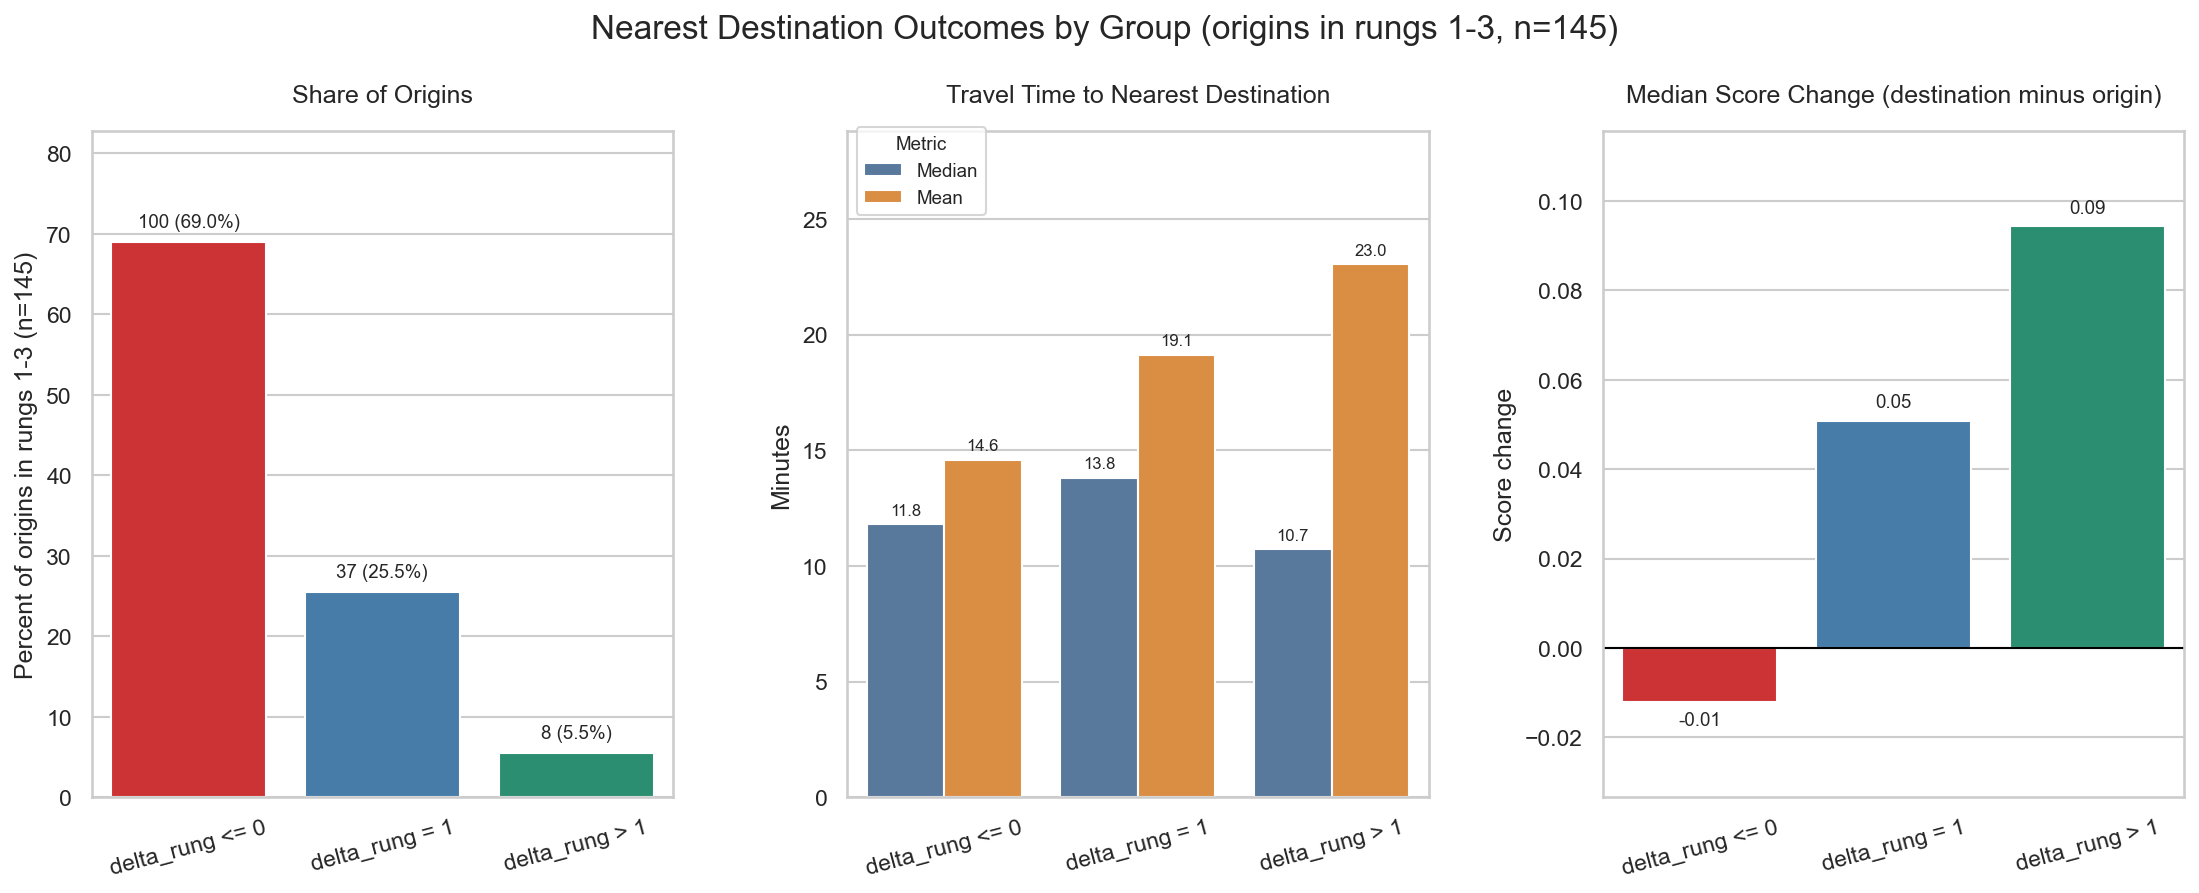

In [93]:
# Plotting table comes from cell 113 (origins in rungs 1-3 only)
plot_df = group_summary.copy()

# Desired group order
group_order = ["delta_rung <= 0", "delta_rung = 1", "delta_rung > 1"]

# Colors for group-based panels (same colors as the map layers in cell 112)
group_palette = {
    "delta_rung <= 0": "#e41a1c",  # red
    "delta_rung = 1":  "#377eb8",  # blue
    "delta_rung > 1":  "#1b9e77"   # green
}

# Colors for travel-time panel
travel_palette = {
    "median_travel": "#4e79a7",  # blue
    "mean_travel": "#f28e2b"     # orange
}

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Panel 1: Share of origins
sns.barplot(
    data=plot_df,
    x="group",
    y="origin_pct",
    hue="group",
    order=group_order,
    palette=group_palette,
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Share of Origins", pad=14)
axes[0].set_xlabel("")
axes[0].set_ylabel(f"Percent of origins in rungs 1-{ELIGIBLE_MAX_RUNG} (n={total_origins})")

ymax0 = plot_df["origin_pct"].max()
axes[0].set_ylim(0, ymax0 * 1.20 if ymax0 > 0 else 1)

for i, grp in enumerate(group_order):
    row = plot_df.loc[plot_df["group"] == grp].iloc[0]
    axes[0].text(
        i,
        row["origin_pct"] + ymax0 * 0.02 if ymax0 > 0 else 0.02,
        f'{int(row["origins"])} ({row["origin_pct"]:.1f}%)',
        ha="center",
        va="bottom",
        fontsize=9
    )

# Panel 2: Travel time
travel_long = plot_df.melt(
    id_vars="group",
    value_vars=["median_travel", "mean_travel"],
    var_name="metric",
    value_name="minutes"
)

sns.barplot(
    data=travel_long,
    x="group",
    y="minutes",
    hue="metric",
    order=group_order,
    hue_order=["median_travel", "mean_travel"],
    palette=travel_palette,
    ax=axes[1]
)

axes[1].set_title("Travel Time to Nearest Destination", pad=14)
axes[1].set_xlabel("")
axes[1].set_ylabel("Minutes")

handles, labels = axes[1].get_legend_handles_labels()
label_map = {
    "median_travel": "Median",
    "mean_travel": "Mean"
}
axes[1].legend(
    handles=handles,
    labels=[label_map.get(l, l) for l in labels],
    title="Metric",
    loc="upper left",
    bbox_to_anchor=(0.0, 1.02),
    frameon=True,
    fontsize=9,
    title_fontsize=9
)

ymax1 = travel_long["minutes"].max()
axes[1].set_ylim(0, ymax1 * 1.25 if ymax1 > 0 else 1)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f", padding=3, fontsize=8)

# Panel 3: Median score change (destination minus origin; negative for the <=0 group)
sns.barplot(
    data=plot_df,
    x="group",
    y="median_score_gain",
    hue="group",
    order=group_order,
    palette=group_palette,
    legend=False,
    ax=axes[2]
)

axes[2].axhline(0, color="black", linewidth=1)
axes[2].set_title("Median Score Change (destination minus origin)", pad=14)
axes[2].set_xlabel("")
axes[2].set_ylabel("Score change")

ymin2 = plot_df["median_score_gain"].min()
ymax2 = plot_df["median_score_gain"].max()
spread2 = ymax2 - ymin2
pad2 = spread2 * 0.20 if spread2 > 0 else 0.5
axes[2].set_ylim(ymin2 - pad2, ymax2 + pad2)

for i, grp in enumerate(group_order):
    row = plot_df.loc[plot_df["group"] == grp].iloc[0]
    y = row["median_score_gain"]
    offset = pad2 * 0.10 if y >= 0 else -pad2 * 0.10
    va = "bottom" if y >= 0 else "top"
    axes[2].text(
        i,
        y + offset,
        f"{y:.2f}",
        ha="center",
        va=va,
        fontsize=9
    )

# Final layout tweaks
for ax in axes:
    ax.tick_params(axis="x", rotation=15)

plt.suptitle(
    f"Nearest Destination Outcomes by Group (origins in rungs 1-{ELIGIBLE_MAX_RUNG}, n={total_origins})",
    fontsize=16, y=0.98
)
plt.subplots_adjust(top=0.85, wspace=0.30)

write_out = os.path.join(base_path, "figures","all_next_nearest_nbhd_3groups.png")
#plt.savefig(write_out, dpi=300, bbox_inches="tight")

# Save the travel-time and score-change panels on their own for the portfolio page
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
for ax, fname in [(axes[1], "nearest_travel_time.png"), (axes[2], "nearest_score_change.png")]:
    bbox = ax.get_tightbbox(renderer).transformed(fig.dpi_scale_trans.inverted()).padded(0.15)
    #fig.savefig(os.path.join(base_path, "figures", fname), dpi=300, bbox_inches=bbox)
plt.show()

## How long to get to the next rung? 

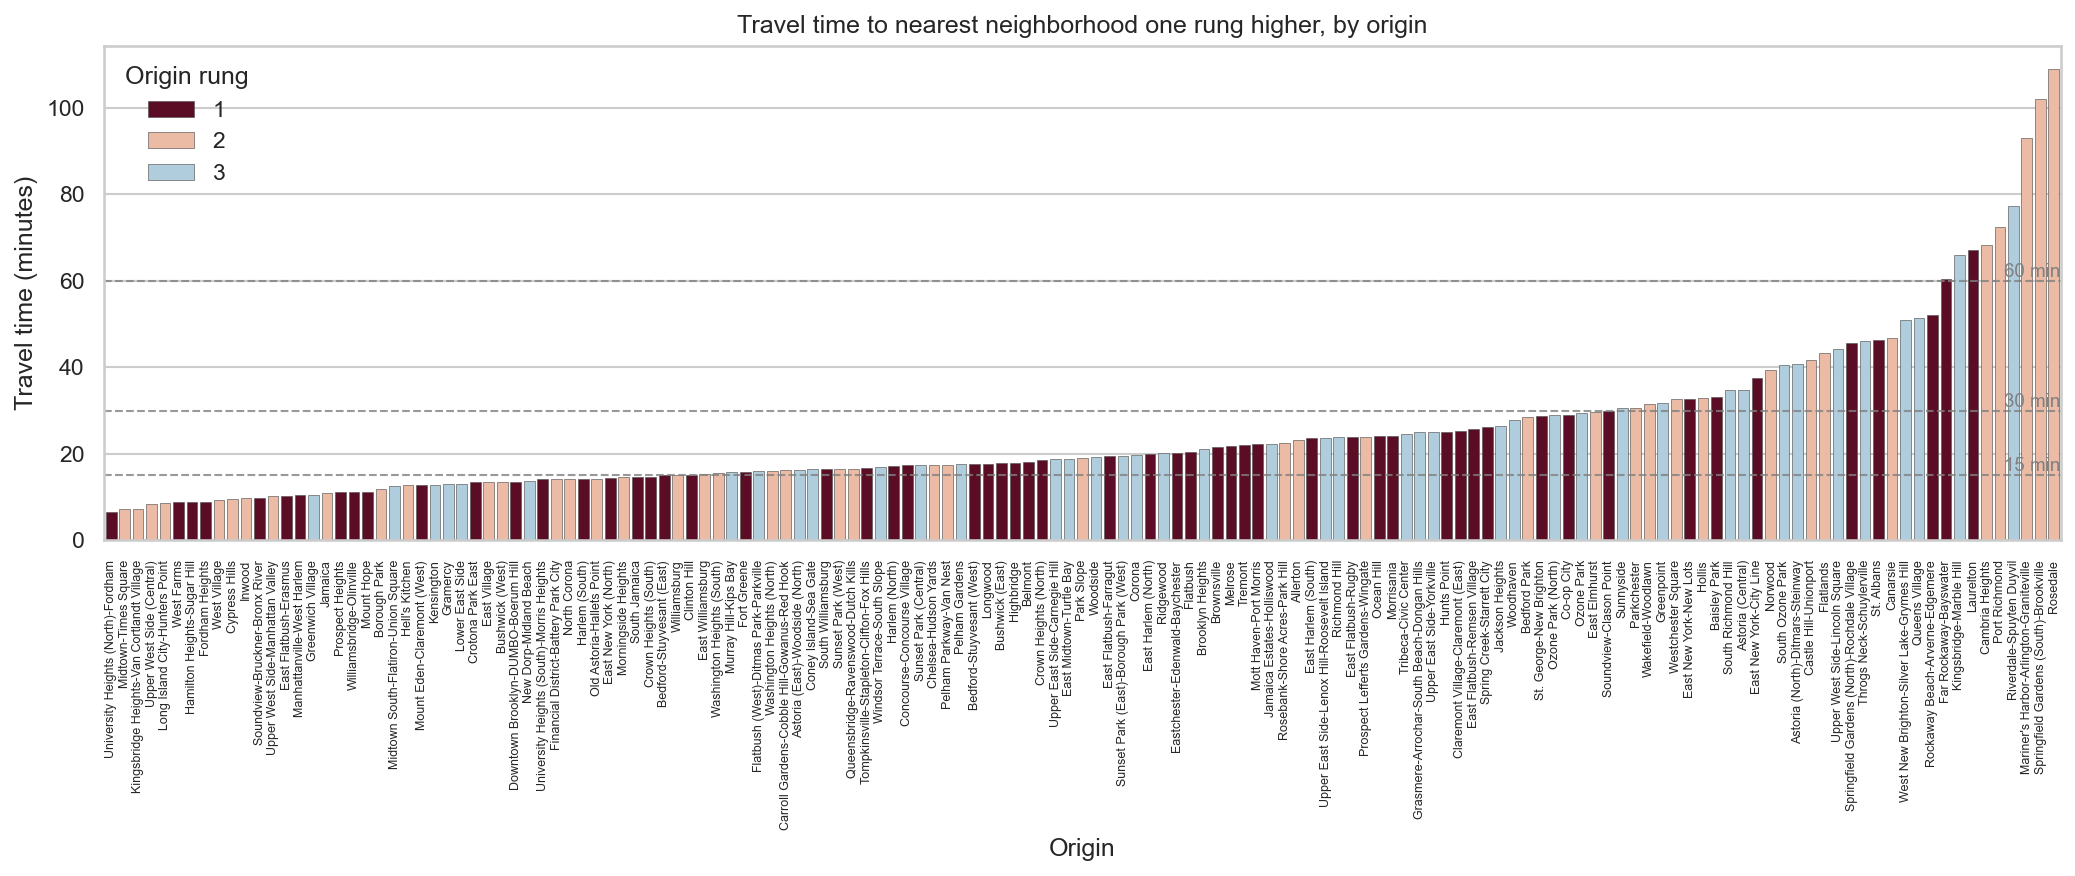

In [95]:
flag2 = cand[(cand["delta_rung"] == 1) & (cand["dest_pos_1_travel_time_rank"] == 1)].copy()

plot_df = flag2.sort_values("travel_min").copy()
plot_df["origin_rung"] = plot_df["origin_rung"].astype(int)

palette = {1: "#67001f", 2: "#f7b799", 3: "#a7d0e4"}   # rungs 1-3, RdBu to match Bridging NYC (rung 4 has no +1 neighbor)

plt.figure(figsize=(14, 6))
ax = sns.barplot(
    data=plot_df,
    x="origin_name", y="travel_min",
    hue="origin_rung", palette=palette,
    order=plot_df["origin_name"],
    dodge=False,
    edgecolor="#555", linewidth=0.3,
)

plt.xticks(rotation=90, fontsize=6)
plt.title("Travel time to nearest neighborhood one rung higher, by origin")
plt.ylabel("Travel time (minutes)")
plt.xlabel("Origin")

for y in [15, 30, 60]:
    ax.axhline(y, color="grey", linestyle="--", linewidth=1, alpha=0.8)
    ax.text(len(plot_df) - 0.5, y, f"{y} min", va="bottom", ha="right", color="grey", fontsize=9)

ax.legend(title="Origin rung", loc="upper left", frameon=False)
plt.tight_layout()
write_out = os.path.join(base_path, "figures","travel_time_all_origins_1_rung.png")
#plt.savefig(write_out, dpi=300, bbox_inches="tight")
plt.show()

145 145
   origin_rung   n  Median   Mean  within30  median_gain
0            1  58   17.97  21.70     86.21         0.05
1            2  45   16.52  27.24     71.11         0.05
2            3  42   23.06  27.04     71.43         0.05


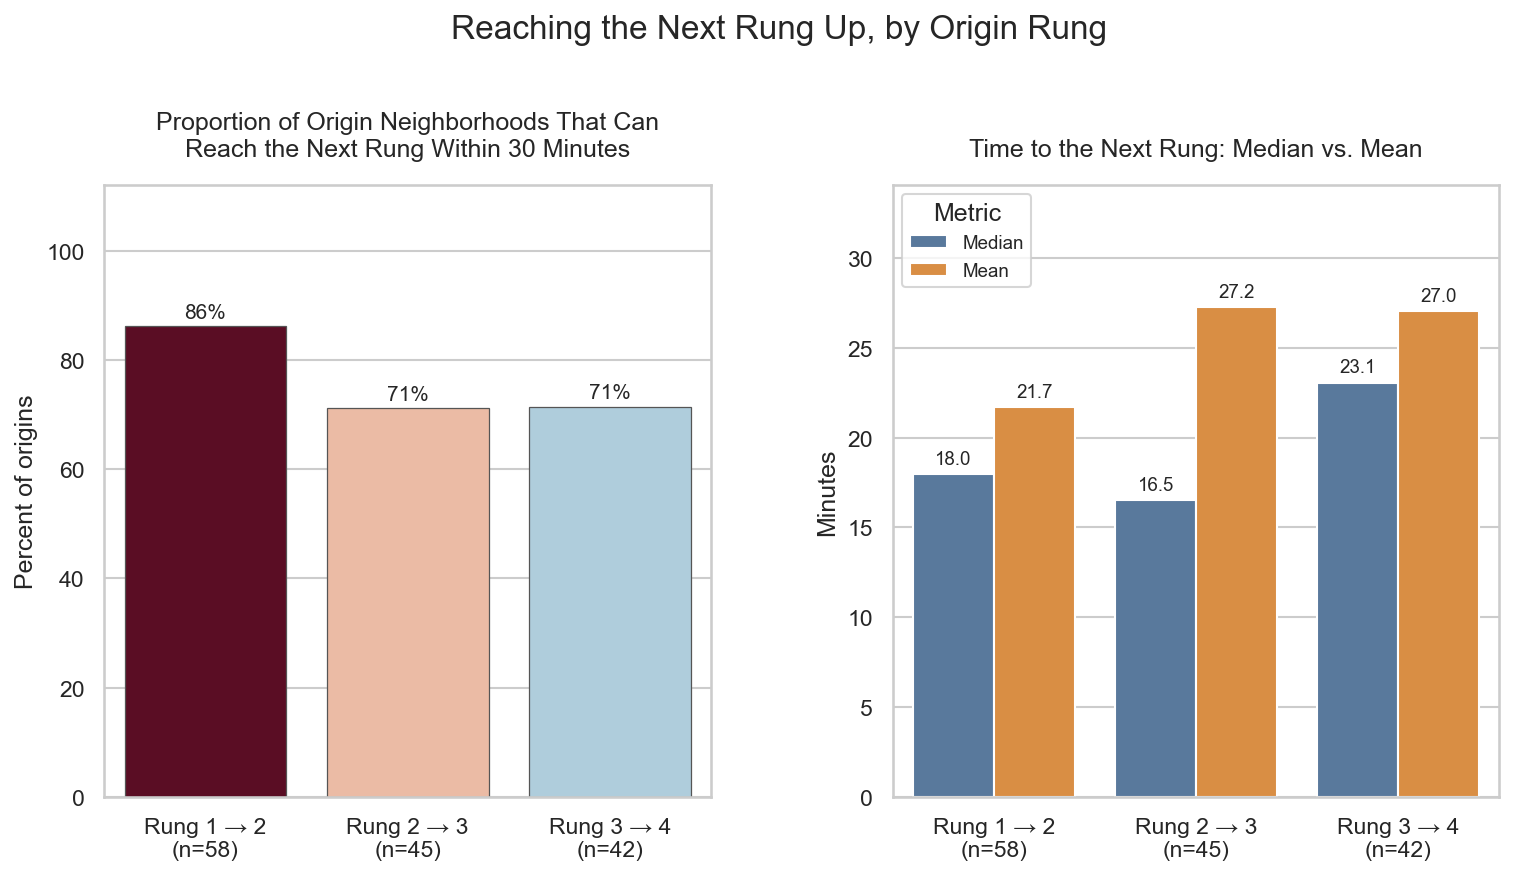

In [96]:
flag2 = cand[(cand["delta_rung"] == 1) & (cand["dest_pos_1_travel_time_rank"] == 1)].copy()

f = flag2[flag2["origin_rung"].isin([1, 2, 3])].copy()
f["origin_rung"] = f["origin_rung"].astype(int)
f["score_gain"] = f["dest_score"] - f["origin_score"]
print(len(f), f["origin"].nunique())            # expect 145, 145

rungs = [1, 2, 3]
rung_palette = {1: "#67001f", 2: "#f7b799", 3: "#a7d0e4"}  # RdBu to match Bridging NYC
travel_palette = {"Median": "#4e79a7", "Mean": "#f28e2b"}

summary = (f.groupby("origin_rung")
             .agg(n=("origin", "size"),
                  Median=("travel_min", "median"),
                  Mean=("travel_min", "mean"),
                  within30=("travel_min", lambda s: 100 * (s <= 30).mean()),
                  median_gain=("score_gain", "median"))
             .reindex(rungs).reset_index())
print(summary.round(2))

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
xlabels = [f"Rung {r} → {r+1}\n(n={int(summary.loc[summary.origin_rung==r,'n'].iloc[0])})" for r in rungs]

# Panel 1: share that can reach the next rung within 30 minutes
sns.barplot(data=summary, x="origin_rung", y="within30", hue="origin_rung",
            order=rungs, palette=rung_palette, legend=False, ax=axes[0], edgecolor="#555", linewidth=0.6)
axes[0].set_title("Proportion of Origin Neighborhoods That Can\nReach the Next Rung Within 30 Minutes", pad=14)
axes[0].set_ylabel("Percent of origins")
axes[0].set_ylim(0, 112)
for i, r in enumerate(rungs):
    v = summary.loc[summary.origin_rung == r, "within30"].iloc[0]
    axes[0].text(i, v + 1.5, f"{v:.0f}%", ha="center", fontsize=10)

# Panel 2: median vs mean travel time to the next rung
tl = summary.melt(id_vars="origin_rung", value_vars=["Median", "Mean"],
                  var_name="metric", value_name="minutes")
sns.barplot(data=tl, x="origin_rung", y="minutes", hue="metric",
            order=rungs, hue_order=["Median", "Mean"], palette=travel_palette, ax=axes[1])
axes[1].set_title("Time to the Next Rung: Median vs. Mean", pad=14)
axes[1].set_ylabel("Minutes")
axes[1].set_ylim(0, tl["minutes"].max() * 1.25)
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.1f", padding=3, fontsize=9)
axes[1].legend(title="Metric", loc="upper left", frameon=True, fontsize=9)

for ax in axes:
    ax.set_xlabel("")
    ax.set_xticks(range(len(rungs)))
    ax.set_xticklabels(xlabels)

plt.suptitle("Reaching the Next Rung Up, by Origin Rung", fontsize=16, y=0.98)
plt.subplots_adjust(top=0.79, wspace=0.30)

write_out = os.path.join(base_path, "figures", "next_rung_travel_by_origin_rung.png")
#plt.savefig(write_out, dpi=300, bbox_inches="tight")
plt.show()

In [94]:
cand[(cand["delta_rung"] ==1) & (cand["origin_rung"]<4)]["travel_min"].describe()

count    3398.000000
mean       63.376438
std        32.792774
min         6.553991
25%        40.856047
50%        57.687427
75%        77.789655
max       240.484023
Name: travel_min, dtype: float64

/var/folders/_1/x0bt13v93p1gch_vhrzdjvfh0000gn/T/ipykernel_43126/547080642.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"{b}\n(n={counts[b]})" for b in order])


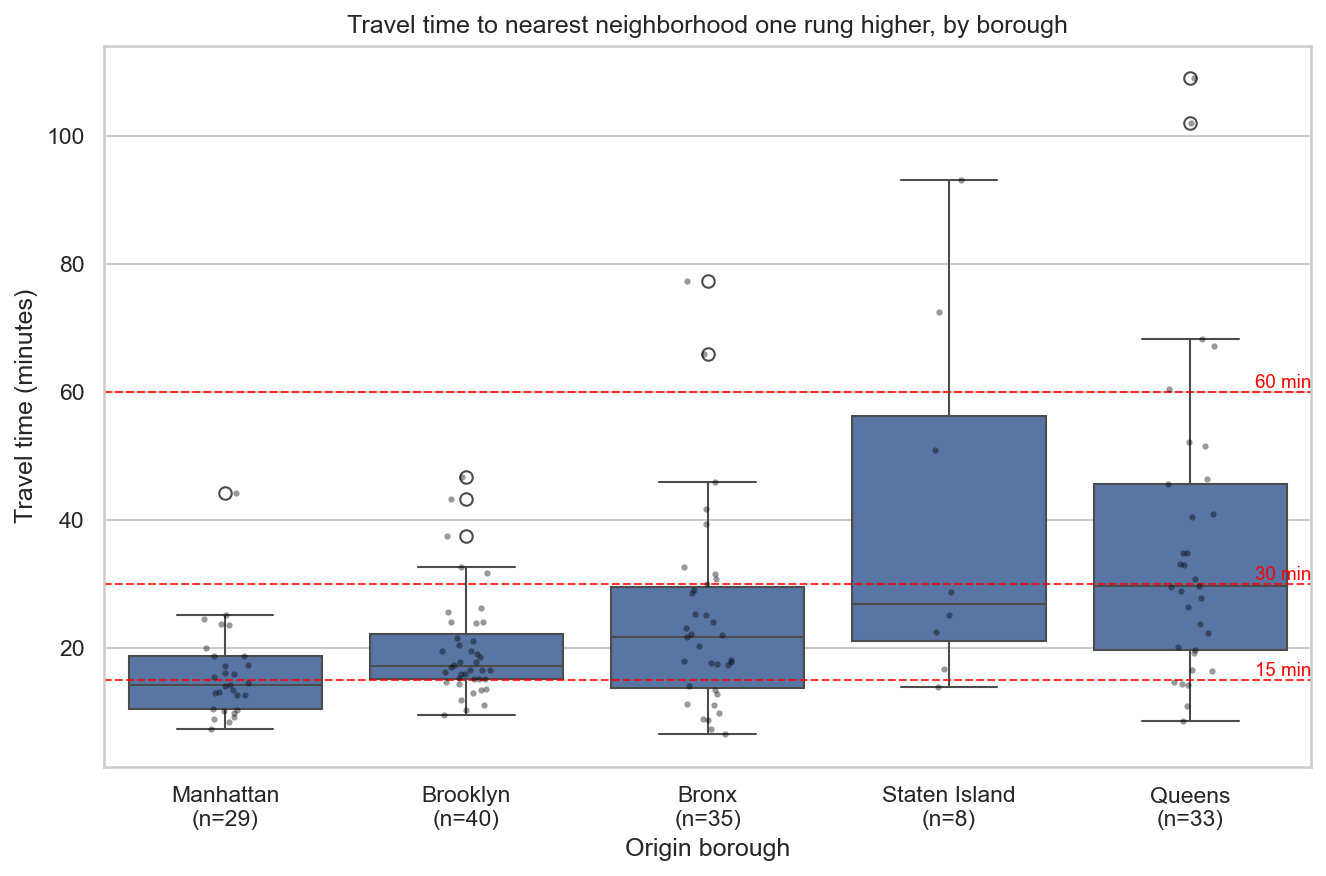

In [98]:
from scipy import stats

boro = nta_gdf[["NTA2020", "BoroName"]].drop_duplicates()
flag2b = flag2.merge(boro, left_on="origin", right_on="NTA2020", how="left")

order = flag2b.groupby("BoroName")["travel_min"].median().sort_values().index

plt.figure(figsize=(9, 6))
ax = sns.boxplot(data=flag2b, x="BoroName", y="travel_min", order=order)
sns.stripplot(data=flag2b, x="BoroName", y="travel_min", order=order,
              color="black", alpha=0.4, size=3)

# label each box with its n
counts = flag2b["BoroName"].value_counts()
ax.set_xticklabels([f"{b}\n(n={counts[b]})" for b in order])

for y in [15, 30, 60]:
    ax.axhline(y, color="red", linestyle="--", linewidth=1, alpha=0.8)
    ax.text(len(order) - 0.5, y, f"{y} min", va="bottom", ha="right", color="red", fontsize=9)

ax.set_title("Travel time to nearest neighborhood one rung higher, by borough")
ax.set_xlabel("Origin borough")
ax.set_ylabel("Travel time (minutes)")
plt.tight_layout()
plt.show()

## Similar exericse, but with a focus on rungs 1 and 2

rung 1-2 origins: 103 | in flag2: 103
origins in flag2 overall: 145 | with any +1 row in cand: 145


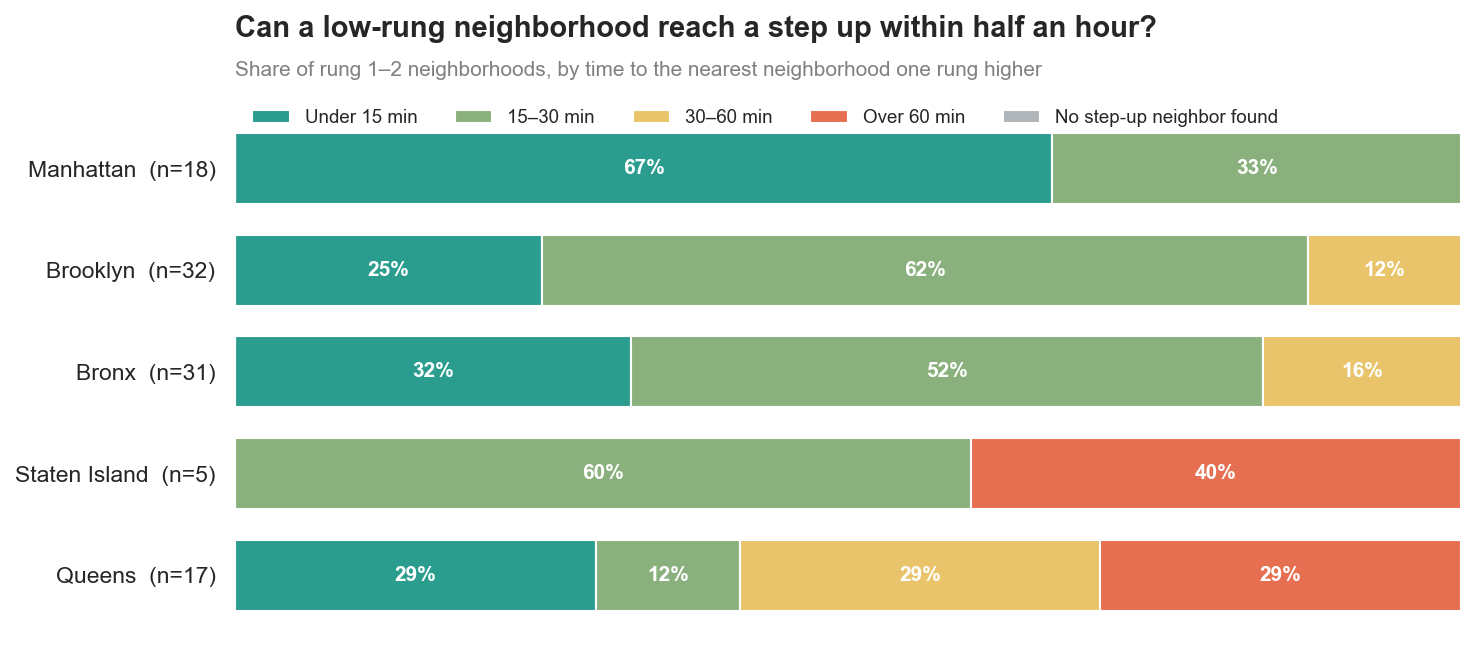

In [99]:
flag2 = cand[(cand["delta_rung"] == 1) & (cand["dest_pos_1_travel_time_rank"] == 1)].copy()

# sanity checks
low = cand[cand["origin_rung"].isin([1, 2])]
print("rung 1-2 origins:", low["origin"].nunique(),
      "| in flag2:", flag2.loc[flag2["origin_rung"].isin([1, 2]), "origin"].nunique())
print("origins in flag2 overall:", flag2["origin"].nunique(),
      "| with any +1 row in cand:", cand.loc[one_rung_mask, "origin"].nunique())

# One row per origin, whether or not it has a +1 neighbor
origins = (cand[["origin", "origin_name", "origin_rung"]].drop_duplicates("origin")
           .merge(boro, left_on="origin", right_on="NTA2020", how="left")
           .merge(flag2[["origin", "travel_min"]], on="origin", how="left"))
origins = origins[origins["origin_rung"].isin([1, 2])]

labels = ["Under 15 min", "15–30 min", "30–60 min", "Over 60 min", "No step-up neighbor found"]
origins["bucket"] = pd.cut(origins["travel_min"], [0, 15, 30, 60, np.inf], labels=labels[:4])
origins["bucket"] = origins["bucket"].cat.add_categories(labels[4]).fillna(labels[4])

share = (origins.groupby(["BoroName", "bucket"], observed=False).size()
                .unstack(fill_value=0)[labels])
n = share.sum(axis=1)
share = share.div(n, axis=0) * 100
share = share.loc[(share[labels[0]] + share[labels[1]]).sort_values().index]  # best on top

colors = ["#2a9d8f", "#8ab17d", "#e9c46a", "#e76f51", "#b0b5ba"]
ax = share.plot(kind="barh", stacked=True, color=colors, figsize=(10, 4.5), width=0.7)

for c in ax.containers:
    ax.bar_label(c, labels=[f"{v:.0f}%" if v >= 6 else "" for v in c.datavalues],
                 label_type="center", color="white", fontsize=10, fontweight="bold")

ax.set_yticklabels([f"{b}  (n={n[b]})" for b in share.index], fontsize=11)
ax.set_xlim(0, 100)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticks([])
for s in ["top", "right", "bottom", "left"]:
    ax.spines[s].set_visible(False)

ax.set_title("Can a low-rung neighborhood reach a step up within half an hour?",
             loc="left", fontsize=14, fontweight="bold", pad=34)
ax.text(0, 1.06, "Share of rung 1–2 neighborhoods, by time to the nearest neighborhood one rung higher",
        transform=ax.transAxes, fontsize=10, color="grey")
ax.legend(ncol=5, loc="upper left", bbox_to_anchor=(0, 1.03), frameon=False, fontsize=9)
plt.tight_layout()
write_out = os.path.join(base_path, "figures", "next_rung_travel_by_boro_rung_1_2.png")
#plt.savefig(write_out, dpi=300, bbox_inches="tight")
plt.show()

## Identify “destination hubs”

In [101]:
# Prep: +1 rung candidates, top-10 destinations, OD pairs, coords
flag3 = cand.loc[cand["delta_rung"].eq(1)].copy()

dest_cols = ["dest", "dest_rung", "dest_score"] + (["dest_name"] if "dest_name" in cand.columns else [])
dest_lookup = cand[dest_cols].drop_duplicates("dest")

def topk_destination_counts(dfp, k=10):
    topk = dfp.loc[dfp["dest_pos_1_travel_time_rank"].le(k)]

    out = (
        topk.groupby("dest", as_index=False)
        .agg(
            n_origins=("origin", "nunique"),
            n_hits=("origin", "size"),
            avg_travel_min=("travel_min", "mean"),
            median_travel_min=("travel_min", "median"),
        )
        .assign(
            share_of_origins=lambda x: x["n_origins"] / dfp["origin"].nunique(),
            top_k=f"Top {k}",
        )
        .merge(dest_lookup, on="dest", how="left")
        .sort_values(["n_origins", "median_travel_min"], ascending=[False, True])
        .reset_index(drop=True)
    )
    return out

top10 = topk_destination_counts(flag3, 10).head(10).copy()

pairs = flag3.loc[
    flag3["dest_pos_1_travel_time_rank"].le(10)
    & flag3["dest"].isin(top10["dest"])
].copy()

# Coordinate lookups
nta_pts = nta_gdf.copy()
nta_pts["pt"] = nta_pts.geometry.representative_point()
nta_pts["lon"], nta_pts["lat"] = nta_pts["pt"].x, nta_pts["pt"].y

coord_lookup = nta_pts[["NTAName", "lat", "lon"]]

origin_lookup = coord_lookup.rename(columns={
    "NTAName": "origin_name",
    "lat": "origin_lat",
    "lon": "origin_lon",
})

dest_lookup_coords = coord_lookup.rename(columns={
    "NTAName": "dest_name",
    "lat": "dest_lat",
    "lon": "dest_lon",
})

pairs = (
    pairs
    .merge(origin_lookup, on="origin_name", how="left")
    .merge(dest_lookup_coords, on="dest_name", how="left")
)

top10 = top10.merge(dest_lookup_coords, on="dest_name", how="left")


# Folium map
# Create map
m = folium.Map(location=[40.7128, -74.0060], zoom_start=11, tiles=None)

esri = "https://server.arcgisonline.com/ArcGIS/rest/services/{}/MapServer/tile/{{z}}/{{y}}/{{x}}"
attr = "Tiles © Esri"

# Default basemap (first one added is shown on load)
folium.TileLayer(esri.format("World_Topo_Map"), attr=attr,
                 name="Esri Topo", max_zoom=19).add_to(m)

add_nta_outlines(m)

# Color scale
vmin, vmax = pairs["travel_min"].min(), pairs["travel_min"].max()
cmap = mpl.colormaps["magma"] 
colors = [mplcolors.to_hex(cmap(i)) for i in np.linspace(0, 1, 256)]

col = bcm.LinearColormap(
    colors=colors,
    vmin=vmin,
    vmax=vmax,
    caption="Travel time (minutes), origin to destination",
)
col.add_to(m)

# Destination-specific line layers
dest_layers = {
    dest_name: folium.FeatureGroup(
        name=f"Origins → {dest_name}",
        show=False,
    ).add_to(m)
    for dest_name in top10["dest_name"]
}

fg_all = folium.FeatureGroup(
    name="All lines (dense)",
    show=False,
).add_to(m)

for r in pairs.itertuples(index=False):
    coords = [(r.origin_lat, r.origin_lon), (r.dest_lat, r.dest_lon)]
    color = col(r.travel_min)

    if r.dest_name in dest_layers:
        folium.PolyLine(
            coords,
            color=color,
            weight=2.5,
            opacity=0.75,
            tooltip=f"{r.origin_name} → {r.dest_name} | {r.travel_min:.1f} min",
        ).add_to(dest_layers[r.dest_name])

    folium.PolyLine(
        coords,
        color=color,
        weight=2,
        opacity=0.35,
    ).add_to(fg_all)

# Destination markers and labels
fg_dests = folium.FeatureGroup(
    name="Top 10 destinations",
    show=True,
).add_to(m)

for r in top10.itertuples(index=False):
    popup_html = f"""
    <div style="min-width:200px">
      <div style="font-weight:700; margin-bottom:6px;">{r.dest_name}</div>
      <div>Origins: {r.n_origins} ({100 * r.share_of_origins:.1f}% of origins)</div>
      <div>Median travel: {r.median_travel_min:.1f} min</div>
    </div>
    """

    loc = (r.dest_lat, r.dest_lon)

    folium.CircleMarker(
        location=loc,
        radius=8,
        color="#1f78b4",
        weight=2,
        fill=True,
        fill_color="#1f78b4",
        fill_opacity=0.85,
        popup=folium.Popup(popup_html, max_width=350),
        tooltip=f"{r.dest_name} (click for details)",
    ).add_to(fg_dests)

    folium.Marker(
        location=loc,
        icon=DivIcon(html=f"""
            <div style="
                font-size: 11px;
                font-weight: 600;
                color: #111;
                text-shadow: 0 0 2px #fff, 0 0 2px #fff;
                transform: translate(10px, -10px);
                white-space: nowrap;">
                {r.dest_name}
            </div>
        """),
    ).add_to(fg_dests)

finish_map(m)
#m.save(os.path.join(base_path, "figures", "top10_attractors_filterable.html"))
m


In [102]:
def make_attractor_summary_text(top10, pairs):
    dest_col = "dest_name" if "dest_name" in top10.columns else "dest"
    score_col = "dest_score" if "dest_score" in top10.columns else None
    rung_col = "dest_rung" if "dest_rung" in top10.columns else None

    n_dest = top10[dest_col].nunique()
    n_origins = pairs["origin"].nunique() if "origin" in pairs.columns else np.nan
    n_links = len(pairs)

    mean_tt = pairs["travel_min"].mean() if "travel_min" in pairs.columns else np.nan
    med_tt = pairs["travel_min"].median() if "travel_min" in pairs.columns else np.nan
    p90_tt = pairs["travel_min"].quantile(0.90) if "travel_min" in pairs.columns else np.nan

    med_dest_score = top10[score_col].median() if score_col else np.nan
    max_dest_score = top10[score_col].max() if score_col else np.nan

    med_dest_rung = top10[rung_col].median() if rung_col else np.nan

    # Top 3 by number of origins reached
    top3 = (
        top10.sort_values(["n_origins", "median_travel_min"], ascending=[False, True])
             [[dest_col, "n_origins", "share_of_origins", "median_travel_min"] + ([score_col] if score_col else [])]
             .head(3)
    )

    top_lines = []
    for i, row in enumerate(top3.itertuples(index=False), start=1):
        vals = row._asdict()
        line = (
            f"{i}. {vals[dest_col]}: "
            f"{vals['n_origins']} origins "
            f"({100*vals['share_of_origins']:.3f}%), "
            f"median travel {vals['median_travel_min']:.3f} min"
        )
        if score_col:
            line += f", score {vals[score_col]:.3f}"
        top_lines.append(line)

    summary_text = (
        "TOP-10 DESTINATION ATTRACTOR SUMMARY\n"
        f"- Destinations shown: {n_dest}\n"
        f"- Unique origins connected: {n_origins}\n"
        f"- Total OD links displayed: {n_links}\n"
        f"- Mean travel time: {mean_tt:.3f} min\n"
        f"- Median travel time: {med_tt:.3f} min\n"
        f"- 90th percentile travel time: {p90_tt:.3f} min\n"
        + (f"- Median destination score: {med_dest_score:.3f}\n" if score_col else "")
        + (f"- Maximum destination score: {max_dest_score:.3f}\n" if score_col else "")
        + (f"- Median destination rung: {med_dest_rung:.3f}\n" if rung_col else "")
        + "- Leading attractors by origin reach:\n"
        + "\n".join([f"  {x}" for x in top_lines])
)

    return summary_text
summary_text = make_attractor_summary_text(top10, pairs)
print(summary_text)

TOP-10 DESTINATION ATTRACTOR SUMMARY
- Destinations shown: 10
- Unique origins connected: 124
- Total OD links displayed: 331
- Mean travel time: 41.228 min
- Median travel time: 39.025 min
- 90th percentile travel time: 62.653 min
- Median destination score: 0.450
- Maximum destination score: 0.527
- Median destination rung: 2.500
- Leading attractors by origin reach:
  1. East Midtown-Turtle Bay: 36 origins (24.828%), median travel 39.405 min, score 0.460
  2. Financial District-Battery Park City: 36 origins (24.828%), median travel 41.567 min, score 0.427
  3. Hell's Kitchen: 35 origins (24.138%), median travel 45.378 min, score 0.440


## Identify “deserts” without any upward destinations given a time budget

In [103]:
thresholds = [15,30,45,60,90]
counts_wide = (
    cand.groupby(["origin", 'origin_rung', 'delta_rung'],as_index=False)
        .agg(**{f"n_dest_within_{t}min": ("travel_min", lambda s, t=t: (s <=t).sum()) for t in thresholds})
)

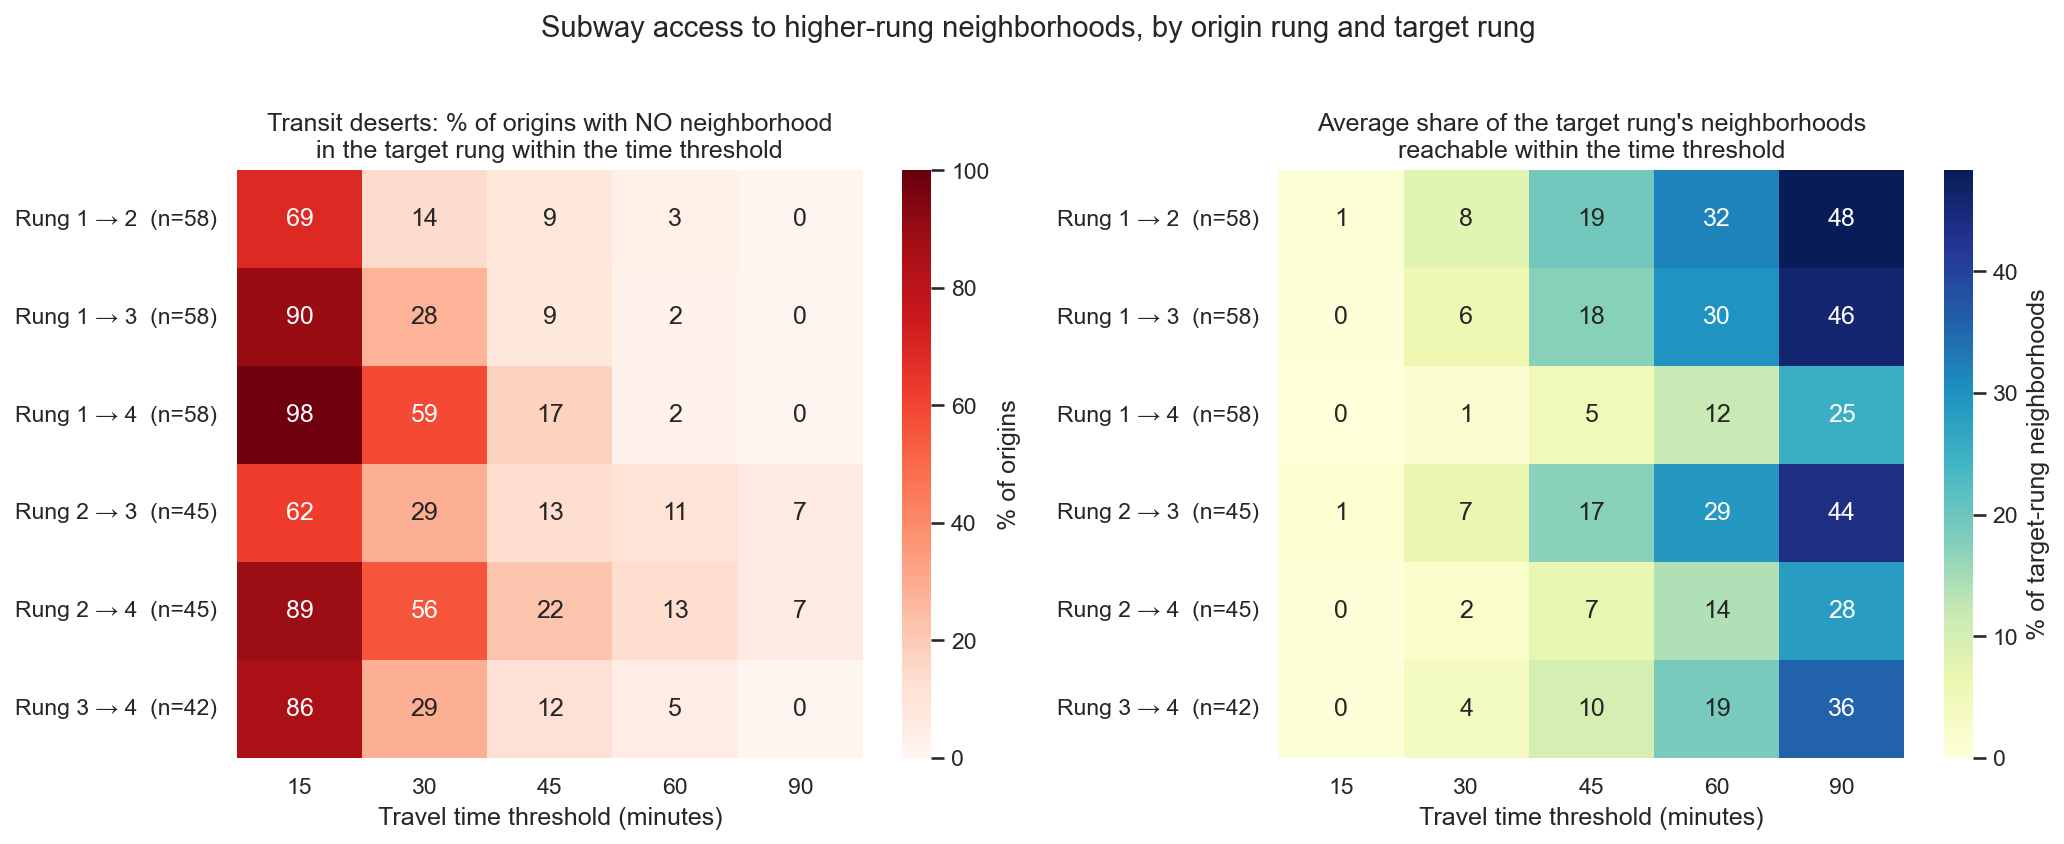

In [104]:

sizes = cand.drop_duplicates("origin")["origin_rung"].value_counts()   # neighborhoods per rung

up = counts_wide[counts_wide["delta_rung"] > 0].copy()
up["target_rung"] = up["origin_rung"] + up["delta_rung"]
up["pair"] = "Rung " + up["origin_rung"].astype(str) + " → " + up["target_rung"].astype(str)

pair_order = (up[["origin_rung", "target_rung", "pair"]].drop_duplicates()
                .sort_values(["origin_rung", "target_rung"])["pair"].tolist())
n_origins = up.groupby("pair")["origin"].nunique()

threshold_cols = [f"n_dest_within_{t}min" for t in thresholds]
long = up.melt(
    id_vars=["origin", "origin_rung", "delta_rung", "target_rung", "pair"],
    value_vars=threshold_cols,
    var_name="threshold",
    value_name="n_destinations",
)
long["minutes"] = long["threshold"].str.extract(r"within_(\d+)min")[0].astype(int)

# Desert flag: this origin reaches NO neighborhood in the target rung within the threshold
long["is_desert"] = long["n_destinations"] == 0
# Normalized access: share of the target rung's neighborhoods that are reachable (same as cell 118)
long["share_reachable"] = 100 * long["n_destinations"] / long["target_rung"].map(sizes)

desert_pct = (long.groupby(["pair", "minutes"])["is_desert"].mean().mul(100)
                  .unstack("minutes").loc[pair_order])
reach_pct = (long.groupby(["pair", "minutes"])["share_reachable"].mean()
                 .unstack("minutes").loc[pair_order])

ylabels = [f"{p}  (n={n_origins[p]})" for p in pair_order]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(desert_pct, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100,
            cbar_kws={"label": "% of origins"}, ax=axes[0])
axes[0].set_title("Transit deserts: % of origins with NO neighborhood\nin the target rung within the time threshold")

sns.heatmap(reach_pct, annot=True, fmt=".0f", cmap="YlGnBu", vmin=0,
            cbar_kws={"label": "% of target-rung neighborhoods"}, ax=axes[1])
axes[1].set_title("Average share of the target rung's neighborhoods\nreachable within the time threshold")

for ax in axes:
    ax.set_xlabel("Travel time threshold (minutes)")
    ax.set_ylabel("")
    ax.set_yticklabels(ylabels, rotation=0)

plt.suptitle("Subway access to higher-rung neighborhoods, by origin rung and target rung", fontsize=14, y=1.02)
plt.tight_layout()
#plt.savefig(os.path.join(base_path, "figures", "delta_rung_heatmap.png"),dpi=300, bbox_inches="tight")
plt.show()

## More time, more choice: one-rung-up options by time budget

Median one-rung-up options by origin rung:
 minutes       15   30   45    60    90
origin_rung                           
1            0.0  2.5  7.5  15.5  21.0
2            0.0  2.0  7.0  12.0  13.0
3            0.0  1.0  4.5   8.0  23.0

Share of origins with 3+ options: within 30 min = 41%, within 45 min = 75%
Share of origins with no option:  within 30 min = 23%, within 45 min = 11%

Average % of one-rung-up neighborhoods reachable, by borough:
 minutes         15    30    45    60    90
BoroName                                  
Bronx          1.0   5.5  18.0  30.7  45.2
Brooklyn       0.5   6.7  16.8  29.6  48.5
Manhattan      2.1  10.6  24.8  40.4  53.1
Queens         0.4   3.5   7.7  14.1  34.8
Staten Island  0.2   2.6   4.1   5.5   8.4


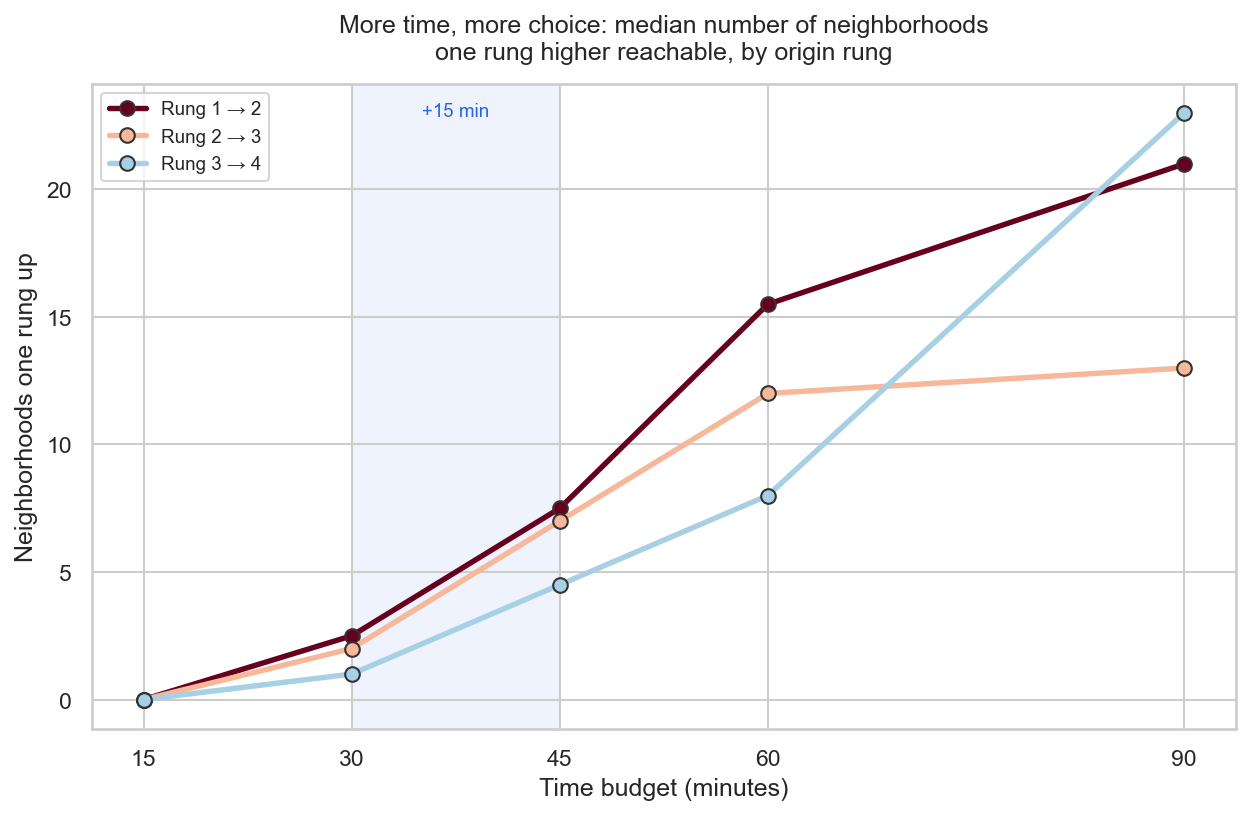

In [106]:
# Builds on `long` from the heatmap cell above, keeping only the one-rung-up step (delta_rung == 1)
step = long[long["delta_rung"] == 1].merge(boro, left_on="origin", right_on="NTA2020", how="left")

# Left panel: median number of one-rung-up neighborhoods reachable, by origin rung
opts = step.groupby(["origin_rung", "minutes"])["n_destinations"].median().unstack("minutes")
# Right panel: average share of the one-rung-up neighborhoods reachable, by origin borough
reach_boro = step.groupby(["BoroName", "minutes"])["share_reachable"].mean().unstack("minutes")

w30 = step[step["minutes"] == 30].set_index("origin")["n_destinations"]
w45 = step[step["minutes"] == 45].set_index("origin")["n_destinations"]
print("Median one-rung-up options by origin rung:\n", opts.round(1))
print("\nShare of origins with 3+ options: within 30 min = {:.0%}, within 45 min = {:.0%}".format((w30 >= 3).mean(), (w45 >= 3).mean()))
print("Share of origins with no option:  within 30 min = {:.0%}, within 45 min = {:.0%}".format((w30 == 0).mean(), (w45 == 0).mean()))
print("\nAverage % of one-rung-up neighborhoods reachable, by borough:\n", reach_boro.round(1))

# Rung colors match Bridging NYC (RdBu); light rungs get a dark marker edge so they read on white
rung_colors = {1: "#67001f", 2: "#f7b799", 3: "#a7d0e4"}

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8.5, 5.6))
x = thresholds

ax.axvspan(30, 45, color="#2563eb", alpha=0.07, zorder=0)
for r in [1, 2, 3]:
    ax.plot(x, opts.loc[r, x].values, marker="o", linewidth=2.6, markersize=7,
            color=rung_colors[r], markeredgecolor="#333", label=f"Rung {r} → {r + 1}")
ax.set_title("More time, more choice: median number of neighborhoods\none rung higher reachable, by origin rung", pad=12)
ax.set_xlabel("Time budget (minutes)")
ax.set_ylabel("Neighborhoods one rung up")
ax.set_xticks(x)
ax.legend(frameon=True, fontsize=9, loc="upper left")
ax.text(37.5, ax.get_ylim()[1] * 0.97, "+15 min", ha="center", va="top", fontsize=9, color="#2563eb")


plt.tight_layout()
#plt.savefig(os.path.join(base_path, "figures", "next_rung_options_by_time.png"), dpi=300, bbox_inches="tight")
plt.show()


In [107]:
budget = 60

higher = cand[(cand["delta_rung"] ==1) & (cand["origin_rung"]<4)].copy()
origins = higher[["origin","origin_name","origin_rung"]].drop_duplicates()

within = (higher[higher["travel_min"] <= budget]
          .groupby("origin")["dest"].nunique()
          .rename("n_higher_within_budget")
          .reset_index())

origin_access = origins.merge(within, on="origin", how="left")
origin_access["n_higher_within_budget"] = origin_access["n_higher_within_budget"].fillna(0).astype(int)

origin_deserts = origin_access[origin_access["n_higher_within_budget"] == 0]
origin_deserts


,origin,origin_name,origin_rung,n_higher_within_budget
60,BX0802,Kingsbridge-Marble Hill,3,0
61,BX0803,Riverdale-Spuyten Duyvil,3,0
131,QN1304,Cambria Heights,2,0
132,QN1305,Laurelton,1,0
133,QN1306,Springfield Gardens (South)-Brookville,2,0
134,QN1307,Rosedale,2,0
135,QN1401,Far Rockaway-Bayswater,1,0
141,SI0106,Port Richmond,2,0
142,SI0107,Mariner's Harbor-Arlington-Graniteville,2,0


In [109]:
import folium
from folium.features import DivIcon

nta_pts = nta_gdf[["NTAName", "geometry"]].copy()
nta_pts["pt"] = nta_pts.geometry.representative_point()
nta_pts["lat"] = nta_pts["pt"].y
nta_pts["lon"] = nta_pts["pt"].x
nta_pts = nta_pts[["NTAName", "lat", "lon"]]

origin_deserts = (origin_deserts
    .merge(nta_pts, left_on="origin_name", right_on="NTAName", how="left")
    .rename(columns={"lat":"origin_lat", "lon":"origin_lon"})
    .drop(columns=["NTAName"])
)

origin_deserts = origin_deserts.dropna(subset=["origin_lat", "origin_lon"]).copy()

# Folium map (Esri Topo basemap, no API key needed)
m = folium.Map(location=[40.7128, -74.0060], zoom_start=11, tiles=None)

folium.TileLayer(
    "https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Esri Topo",
    max_zoom=19,
).add_to(m)

# NTA outlines for context
add_nta_outlines(m)

# Rung colors: same RdBu scaling as the rung maps (rung 1 = red, rung 4 = blue)
RUNG_CMAP = mpl.colormaps["RdBu"]
def rung_color(r):
    return mplcolors.to_hex(RUNG_CMAP((int(r) - 1) / 3))

# Only rungs 1-3 can be deserts (rung 4 has no higher rung)
legend_rungs = [1, 2, 3]
rung_counts = origin_deserts["origin_rung"].value_counts()

# One layer per rung so you can toggle deserts by rung
layers = {}
for rung in sorted(origin_deserts["origin_rung"].unique()):
    layers[rung] = folium.FeatureGroup(name=f'Rung {rung}{" (lowest)" if rung == 1 else ""}: {int(rung_counts.get(rung, 0))} neighborhoods', show=True).add_to(m)

# Add circles (no lines)
for r in origin_deserts.itertuples(index=False):
    fg = layers.get(r.origin_rung)

    folium.CircleMarker(
        location=(r.origin_lat, r.origin_lon),
        radius=7,
        color="#333333",
        weight=1.5,
        fill=True,
        fill_color=rung_color(r.origin_rung),
        fill_opacity=0.9,
    ).add_to(fg)

    # Optional: always-on label (comment out if too cluttered)
    folium.Marker(
        location=(r.origin_lat, r.origin_lon),
        icon=DivIcon(html=f"""
            <div style="
                font-size: 10px;
                font-weight: 600;
                color: #111;
                text-shadow: 0 0 2px #fff, 0 0 2px #fff;
                transform: translate(8px, -8px);
                white-space: nowrap;">
                {r.origin_name}
            </div>
        """)
    ).add_to(fg)

# Legend that states the time budget, and collapsed layer menu
add_map_legend(m, f"No neighborhood one rung up within {budget} min", [
    (rung_color(r), f'Rung {r}{" (lowest)" if r == 1 else ""}: {int(rung_counts.get(r, 0))} neighborhoods', "dot")
    for r in legend_rungs
], note="By subway. Dot color is the origin's own rung.")
finish_map(m)

#m.save(os.path.join(base_path, "figures", "origin_deserts_circles_only.html"))
m